# Detekcja hejtu w komentarzach - 10 modeli, fine-tuning, ewaluacja, adnotacja

Etykiety: **1 = hate, 0 = no hate**.

| # | Klucz modelu | Punkt startowy | Trening |
|---|---|---|---|
| 1 | `herbert_hs` | `dkleczek/Polish-Hate-Speech-Detection-Herbert-Large` (HerBERT-HS) | Gotowy model, bez dodatkowego dotrenowania |
| 2 | `herbert_hs_banpl` | `dkleczek/Polish-Hate-Speech-Detection-Herbert-Large` (HerBERT-HS) | Dotrenowanie na BAN-PL |
| 3 | `herbert_base_poleval` | `allegro/herbert-large-cased` | Dotrenowanie na PolEval 2019 |
| 4 | `herbert_base_banpl` | `allegro/herbert-large-cased` | Dotrenowanie na BAN-PL |
| 5 | `roberta_base_poleval` | `sdadas/polish-roberta-base-v2` | Dotrenowanie na PolEval 2019 |
| 6 | `roberta_base_banpl` | `sdadas/polish-roberta-base-v2` | Dotrenowanie na BAN-PL |
| 7 | `polbert_cb` | `ptaszynski/bert-base-polish-cyberbullying` (Polbert-CB) | Gotowy model, bez dodatkowego dotrenowania |
| 8 | `polbert_cb_banpl` | `ptaszynski/bert-base-polish-cyberbullying` (Polbert-CB) | Dotrenowanie na BAN-PL |
| 9 | `polbert_base_poleval` | `dkleczek/bert-base-polish-uncased-v1` | Dotrenowanie na PolEval 2019 |
| 9 | `polbert_base_banpl` | `dkleczek/bert-base-polish-uncased-v1` | Dotrenowanie na BAN-PL |

Wszystko zapisuje się do folderu `outputs` i **każdy etap jest wznawialny** (jeśli wynik już jest na dysku, etap jest pomijany; ustaw `FORCE_*` w konfiguracji, żeby przeliczyć od nowa).

## 1. Importy, konfiguracja, urządzenie (MPS)

In [ ]:
%pip install -q transformers torch datasets pandas numpy scikit-learn scipy matplotlib seaborn tqdm sentencepiece sacremoses ipywidgets openpyxl pyzipper accelerate pyzipper

In [1]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"      # operacje nieobsługiwane na MPS spadają na CPU
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import gc, glob, itertools, json, math, platform, random, shutil, sys, time, zipfile
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from scipy.stats import spearmanr
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, cohen_kappa_score,
                             matthews_corrcoef, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
import transformers
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 200)
print("python", platform.python_version(), "| torch", torch.__version__, "| transformers", transformers.__version__)

python 3.14.5 | torch 2.14.1 | transformers 5.19.0


In [2]:
# =============================== KONFIGURACJA ===============================
DEBUG_MODE = False         # True = szybki test całego pipeline'u na małych próbkach

# ---- ścieżki
COMMENTS_CSV = "../comments_examples/comments.csv"
OUT = Path("outputs")                  # wszystkie wyniki 
DIR_MODELS = OUT / "models"               # dotrenowane modele (do ponownego użycia bez fine-tuningu)
DIR_DATA = OUT / "data"                   # przetworzone zbiory (train/val/test)
DIR_EVAL = OUT / "evaluation"             # ewaluacja na testach
DIR_PRED = OUT / "comments_predictions"   # predykcje comments.csv per model
DIR_ANN = OUT / "annotation"              # próbka do adnotacji, pliki dla adnotatorów
DIR_ANN_DONE = DIR_ANN / "completed"      # tu wrzucasz uzupełnione pliki adnotatorów
DIR_AGR = OUT / "agreement"               # współczynniki zgodności
DIR_CMP = OUT / "model_vs_annotation"     # porównanie modeli z adnotacją
DIR_FIG = OUT / "figures"
for d in [DIR_MODELS, DIR_DATA, DIR_EVAL, DIR_PRED, DIR_ANN, DIR_ANN_DONE, DIR_AGR, DIR_CMP, DIR_FIG]:
    d.mkdir(parents=True, exist_ok=True)

# ---- zbiory treningowe/testowe
# PolEval 2019 Task 6-1 (binarny): z HF; gdyby się nie pobrało, podaj lokalne pliki (csv/tsv z kolumnami text,label)
POLEVAL_HF_CANDIDATES = [("poleval2019_cyberbullying", "task01"), ("community-datasets/poleval2019_cyberbullying", "task01")]
# POLEVAL_LOCAL = {"train": None, "test": None}        # np. {"train": "data/poleval_train.csv", "test": "data/poleval_test.csv"}

# BAN-PL: publiczne 24 000 próbek jest na GitHubie (NASK-NLP/BAN-PL, folder data/) jako zip chroniony hasłem.
# Pobierz zip, hasło jest w tym samym folderze na GitHubie. Opcje: podaj zip+hasło ALBO folder z rozpakowanymi plikami.
# Jeśli w BAN-PL nie ma gotowego splitu train/test, zostanie wykonany stratyfikowany split:
BANPL_TEST_SIZE = 0.10
VAL_SIZE = 0.10                   # część treningu odłożona na walidację (early stopping)
BANPL_ZIP = "data/BAN-PL_1.zip"
BANPL_ZIP_PASSWORD = "BAN-PL_1"    # hasło z GitHuba
BANPL_DIR = "data/ban-pl"          # folder z rozpakowanymi plikami csv/tsv/xlsx (do niego rozpakuje się zip)
BANPL_TEXT_COL = None             # None = autodetekcja (text/content/comment/...)
BANPL_LABEL_COL = None            # None = autodetekcja (label/harmful/class/...)

# ---- trening
SEED = 42
EPOCHS = 3
EARLY_STOP_PATIENCE = 2
WARMUP_RATIO = 0.06
WEIGHT_DECAY = 0.01
GRAD_CLIP = 1.0
USE_CLASS_WEIGHTS = True           # ważona strata przy niezbalansowanych klasach (PolEval ~9% hate)
GRADIENT_CHECKPOINTING = True      # oszczędza pamięć na Macu kosztem czasu (dla modeli large polecane)
TRAIN_MAX_LEN = {"poleval": 128, "banpl": 256}     # długość przy treningu (krótsza = szybciej)
TRAIN_BATCH = {"large": 8, "base": 16}             # rozmiar batcha (mikro-batch)
GRAD_ACCUM = {"large": 4, "base": 2}               # akumulacja gradientu: efektywny batch = batch*accum
LEARNING_RATE = {"large": 1e-5, "base": 5e-5}      # base: 5e-5 jak w artykule BAN-PL; large przy 5e-5 bywa niestabilny
MAX_TRAIN_SAMPLES = {"poleval": None, "banpl": None}   # np. {"banpl": 8000} = podpróbka dla szybkości

# ---- modele: gotowe checkpointy (jak w artykule BAN-PL) i punkty startowe fine-tuningu
HERBERT_READY = "dkleczek/Polish-Hate-Speech-Detection-Herbert-Large"      # HerBERT-HS: gotowy detektor hejtu
POLBERT_READY = "ptaszynski/bert-base-polish-cyberbullying"                # Polbert-CB: gotowy detektor cyberprzemocy (dane PolEval)
POLBERT_BASE = "dkleczek/bert-base-polish-uncased-v1"                      # czysty Polbert (bez głowy do hejtu)
ROBERTA_BASE = "sdadas/polish-roberta-base-v2"                             # RoBERTa base v2
HERBERT_BASE = "allegro/herbert-large-cased"                               # czysty HerBERT (bez głowy do hejtu)   

# Gotowe modele mogą mieć odwróconą kolejność klas. Notebook wykrywa ją z id2label; jeśli etykiety są generyczne (LABEL_0/LABEL_1), zakłada 1=hate.
HATE_INDEX_OVERRIDE = {}

# ---- czyszczenie tekstu (artefakty \n, @anonymized_account, {USERNAME}, {URL}, [surname], [pseudonym], ...)
CLEAN_TRAIN_DATA = True              # PolEval + BAN-PL: usuń artefakty anonimizacji i znaki nowej linii
CLEAN_COMMENTS_FOR_MODELS = True     # ta sama normalizacja tekstu komentarzy podawanego modelom (oryginał zostaje w plikach)
DATA_VERSION = "clean_v1" if CLEAN_TRAIN_DATA else "raw"   # wersja cache zbiorów w outputs/data/

# ---- inferencja
THRESHOLD = 0.5
INFER_MAX_LEN = 512
INFER_STRIDE = 128                 # okna z nakładką dla długich komentarzy (wynik = max po oknach)
INFER_BATCH = 16                   # liczba tekstów na batch
INFER_CHUNK_BATCH = 16
UNCERTAIN_BAND = 0.10              # |p_hate - 0.5| < band => flaga "uncertain"
INCLUDE_UNTUNED_BASELINES_IN_ENSEMBLE = False   # nietrenowane modele (losowa głowa) poza ensemble/stratyfikacją

# ---- adnotacja
ANNOTATORS = ["A1", "A2", "A3", "A4"]
ANN_N_PER_STRATUM = 40             # ile komentarzy z każdej warstwy (wg liczby modeli głosujących na hate)
ANN_MIN_CHARS = 3
BOOTSTRAP_N = 1000

# ---- wznawianie / wymuszanie przeliczenia
FORCE_RETRAIN = False
FORCE_REEVAL = False
FORCE_REPREDICT = False

if DEBUG_MODE:
    EPOCHS = 1; MAX_TRAIN_SAMPLES = {"poleval": 300, "banpl": 300}; BOOTSTRAP_N = 100; ANN_N_PER_STRATUM = 5
    OUT = Path("outputs_debug")
    DIR_MODELS, DIR_DATA, DIR_EVAL, DIR_PRED, DIR_ANN, DIR_ANN_DONE, DIR_AGR, DIR_CMP, DIR_FIG = [
        OUT / x for x in ["models", "data", "evaluation", "comments_predictions", "annotation", "annotation/completed",
                          "agreement", "model_vs_annotation", "figures"]]
    for d in [DIR_MODELS, DIR_DATA, DIR_EVAL, DIR_PRED, DIR_ANN, DIR_ANN_DONE, DIR_AGR, DIR_CMP, DIR_FIG]:
        d.mkdir(parents=True, exist_ok=True)
    print("*** TRYB DEBUG: małe próbki, 1 epoka, wyniki do", OUT)

In [3]:
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

if torch.cuda.is_available():
    device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
    print("UWAGA: brak GPU/MPS – fine-tuning modeli large na CPU będzie bardzo wolny.")
print("Urządzenie:", device, "| MPS:", torch.backends.mps.is_available())

def free_memory():
    gc.collect()
    if device.type == "mps":
        torch.mps.empty_cache()
    elif device.type == "cuda":
        torch.cuda.empty_cache()

# zapis konfiguracji i środowiska (reprodukowalność)
cfg_dump = {k: (str(v) if isinstance(v, Path) else v) for k, v in globals().items()
            if k.isupper() and not k.startswith("_") and "PASSWORD" not in k and isinstance(v, (int, float, str, bool, dict, list, tuple, Path, type(None)))}
cfg_dump.update({"timestamp": datetime.now().isoformat(), "torch": torch.__version__, "transformers": transformers.__version__,
                 "python": platform.python_version(), "device": str(device)})
(OUT / "run_config.json").write_text(json.dumps(cfg_dump, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

Urządzenie: mps | MPS: True


2233

## 2. Funkcje pomocnicze: metryki i współczynniki zgodności
(Zaimplementowane ręcznie; sprawdzone na przykładach wzorcowych: Fleiss κ = 0,210 oraz Krippendorff α = 0,743 z Wikipedii, metryki zgodne ze `sklearn`.)

In [4]:
def confusion_counts(y_true, y_pred, w=None):
    y_true = np.asarray(y_true).astype(int); y_pred = np.asarray(y_pred).astype(int)
    w = np.ones(len(y_true)) if w is None else np.asarray(w, dtype=float)
    tp = w[(y_true == 1) & (y_pred == 1)].sum(); tn = w[(y_true == 0) & (y_pred == 0)].sum()
    fp = w[(y_true == 0) & (y_pred == 1)].sum(); fn = w[(y_true == 1) & (y_pred == 0)].sum()
    return tn, fp, fn, tp


def _safe_div(a, b):
    return float(a / b) if b > 0 else 0.0


def _f1(p, r):
    return _safe_div(2 * p * r, p + r)


def expected_calibration_error(y_true, p, n_bins=10):
    y_true = np.asarray(y_true); p = np.asarray(p)
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, bins[1:-1]), 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(y_true[m].mean() - p[m].mean())
    return float(ece)


def binary_metrics(y_true, y_prob=None, threshold=0.5, y_pred=None, sample_weight=None):
    y_true = np.asarray(y_true).astype(int)
    if y_pred is None:
        y_pred = (np.asarray(y_prob) >= threshold).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    w = None if sample_weight is None else np.asarray(sample_weight, dtype=float)
    tn, fp, fn, tp = confusion_counts(y_true, y_pred, w)
    p1 = _safe_div(tp, tp + fp); r1 = _safe_div(tp, tp + fn)
    p0 = _safe_div(tn, tn + fn); r0 = _safe_div(tn, tn + fp)
    f1_1 = _f1(p1, r1); f1_0 = _f1(p0, r0)
    n = tn + fp + fn + tp
    out = {
        "n": int(len(y_true)), "n_hate_true": int((y_true == 1).sum()), "n_hate_pred": int((y_pred == 1).sum()),
        "accuracy": _safe_div(tp + tn, n), "precision_hate": p1, "recall_hate": r1, "f1_hate": f1_1,
        "precision_nohate": p0, "recall_nohate": r0, "f1_nohate": f1_0,
        "macro_f1": (f1_1 + f1_0) / 2, "specificity": r0,
        "balanced_accuracy": (r1 + r0) / 2,
        "tn": float(tn), "fp": float(fp), "fn": float(fn), "tp": float(tp),
    }
    # MCC / kappa (z wagami, jeśli podane)
    den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    out["mcc"] = float((tp * tn - fp * fn) / den) if den > 0 else 0.0
    po = (tp + tn) / n if n > 0 else 0.0
    pe = (((tp + fp) * (tp + fn)) + ((tn + fn) * (tn + fp))) / (n * n) if n > 0 else 0.0
    out["cohen_kappa"] = float((po - pe) / (1 - pe)) if pe < 1 else 0.0
    if y_prob is not None and len(np.unique(y_true)) == 2:
        y_prob = np.asarray(y_prob, dtype=float)
        out["roc_auc"] = float(roc_auc_score(y_true, y_prob, sample_weight=w))
        out["pr_auc"] = float(average_precision_score(y_true, y_prob, sample_weight=w))
        out["brier"] = float(brier_score_loss(y_true, y_prob, sample_weight=w))
        out["ece"] = expected_calibration_error(y_true, y_prob)
    else:
        out["roc_auc"] = out["pr_auc"] = out["brier"] = out["ece"] = np.nan
    return out


def bootstrap_ci(y_true, y_pred, metric="macro_f1", n_boot=1000, seed=42, alpha=0.05, w=None):
    # szybki bootstrap na samych predykcjach binarnych
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true).astype(int); y_pred = np.asarray(y_pred).astype(int)
    w = None if w is None else np.asarray(w, dtype=float)
    n = len(y_true); vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        m = binary_metrics(y_true[idx], y_pred=y_pred[idx], sample_weight=None if w is None else w[idx])
        vals.append(m[metric])
    lo, hi = np.percentile(vals, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(lo), float(hi)


# ---------------------------------------------------------------- zgodność adnotatorów
def pairwise_agreement(df_ann):
    cols = list(df_ann.columns)
    kappa = pd.DataFrame(np.nan, index=cols, columns=cols); pct = kappa.copy(); pabak = kappa.copy(); nitems = kappa.copy()
    for a, b in itertools.product(cols, cols):
        m = df_ann[a].notna() & df_ann[b].notna()
        nitems.loc[a, b] = m.sum()
        if m.sum() == 0:
            continue
        x = df_ann.loc[m, a].astype(int); y = df_ann.loc[m, b].astype(int)
        po = (x == y).mean()
        pct.loc[a, b] = po; pabak.loc[a, b] = 2 * po - 1
        kappa.loc[a, b] = 1.0 if a == b else (cohen_kappa_score(x, y) if len(set(x) | set(y)) > 1 else np.nan)
    return kappa, pct, pabak, nitems


def fleiss_kappa_from_counts(counts):
    counts = np.asarray(counts, dtype=float)
    N, k = counts.shape
    n = counts.sum(axis=1)[0]
    p_j = counts.sum(axis=0) / (N * n)
    P_i = ((counts ** 2).sum(axis=1) - n) / (n * (n - 1))
    P_bar = P_i.mean(); P_e = (p_j ** 2).sum()
    return float((P_bar - P_e) / (1 - P_e)) if P_e < 1 else np.nan


def fleiss_kappa(df_ann):
    d = df_ann.dropna().astype(int)
    if len(d) == 0 or d.shape[1] < 2:
        return np.nan, 0
    counts = np.stack([(d == 0).sum(axis=1), (d == 1).sum(axis=1)], axis=1)
    return fleiss_kappa_from_counts(counts), len(d)


def gwet_ac1(df_ann):
    # AC1 (Gwet) dla wielu adnotatorów, kategorie binarne, przypadki kompletne
    d = df_ann.dropna().astype(int)
    if len(d) == 0 or d.shape[1] < 2:
        return np.nan, 0
    r = d.shape[1]
    pos = d.sum(axis=1).values
    pa = np.mean((pos * (pos - 1) + (r - pos) * (r - pos - 1)) / (r * (r - 1)))
    pi = pos.mean() / r
    pe = 2 * pi * (1 - pi)
    return float((pa - pe) / (1 - pe)) if pe < 1 else np.nan, len(d)


def krippendorff_alpha_nominal(df_ann):
    # wartości: 0/1 lub NaN; obsługuje braki; jednostki z <2 ocenami pomijane
    vals = df_ann.values
    cats = sorted({int(v) for v in vals[~np.isnan(vals)]})
    if len(cats) == 0:
        return np.nan
    cidx = {c: i for i, c in enumerate(cats)}
    k = len(cats)
    o = np.zeros((k, k))
    for row in vals:
        r = row[~np.isnan(row)].astype(int)
        m = len(r)
        if m < 2:
            continue
        cnt = np.zeros(k)
        for v in r:
            cnt[cidx[v]] += 1
        for c in range(k):
            for c2 in range(k):
                pairs = cnt[c] * (cnt[c2] - (1 if c == c2 else 0))
                o[c, c2] += pairs / (m - 1)
    n_c = o.sum(axis=1); n = n_c.sum()
    if n <= 1:
        return np.nan
    Do = (o.sum() - np.trace(o)) / n
    De = (n * n - (n_c ** 2).sum()) / (n * (n - 1))
    return float(1 - Do / De) if De > 0 else np.nan


def bootstrap_alpha(df_ann, n_boot=500, seed=42):
    rng = np.random.default_rng(seed)
    n = len(df_ann); vals = []
    for _ in range(n_boot):
        s = df_ann.iloc[rng.integers(0, n, n)]
        a = krippendorff_alpha_nominal(s)
        if not np.isnan(a):
            vals.append(a)
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))) if vals else (np.nan, np.nan)


def build_gold(df_ann, adjudicated=None):
    # df_ann: kolumny adnotatorów (0/1/NaN). Zwraca DataFrame z votes, share, gold_majority, status
    votes_hate = df_ann.sum(axis=1, skipna=True)
    n_ann = df_ann.notna().sum(axis=1)
    share = votes_hate / n_ann.replace(0, np.nan)
    gold = pd.Series(np.nan, index=df_ann.index)
    gold[share > 0.5] = 1; gold[share < 0.5] = 0
    status = pd.Series("majority", index=df_ann.index)
    status[share.isna()] = "no_annotations"
    status[share == 0.5] = "tie"
    status[(share == 0) | (share == 1)] = "unanimous"
    if adjudicated is not None:
        adj = adjudicated.reindex(df_ann.index)
        m = (status == "tie") & adj.notna()
        gold[m] = adj[m]; status[m] = "adjudicated"
    return pd.DataFrame({"n_annotators": n_ann, "votes_hate": votes_hate, "hate_share": share,
                         "gold": gold, "gold_status": status})

### Czyszczenie tekstu i wyrównanie etykiet gotowych modeli

`clean_text` usuwa artefakty anonimizacji (`@anonymized_account`, `{USERNAME}`, `{URL}`, `[surname]`, `[pseudonym]`, `[address]`, `[email]`, `[phonenumber]`, `[number]` i inne `{PLACEHOLDERY}`), znaki nowej linii (prawdziwe i zapisane jako `\n`), linki, @wzmianki, encje HTML i znaki sterujące. Emoji i ozdobniki zostają (artykuł o BAN-PL traktuje je jako informację). `align_head_to_hate_idx` zapewnia, że w każdym modelu klasa 1 oznacza hate.

In [5]:
# ---------------------------------------------------------------- czyszczenie tekstu
import re, html

_PH_WORDS = r"username|user|url|surname|pseudonym|address|email|phonenumber|phone|number|name|link|anonymized_account|anonymized"
# nick na początku wypowiedzi: {USERNAME}: , USERNAME: , @anonymized_account, (razem z dwukropkiem/przecinkiem)
_RE_USER_LEAD = re.compile(r"(?:\{\s*USERNAME\s*\}|(?<!\w)(?-i:USERNAME)(?=\s*:)|@\s*anonymized_\w+)\s*[:,]?", re.I)
# [surname] [pseudonym] [address] [email] [phonenumber] [number] {URL} ... (także z # z przodu: #[pseudonym])
_RE_PLACEHOLDER = re.compile(r"#?[\[\{]\s*(?:%s)\s*[\]\}]" % _PH_WORDS, re.I)
_RE_CURLY_ANY = re.compile(r"\{\s*[A-Za-z_]{2,25}\s*\}")                 # inne {PLACEHOLDERY}
_RE_URL = re.compile(r"(?:https?://|www\.)\S+", re.I)                    # prawdziwe linki (komentarze YouTube)
_RE_MENTION = re.compile(r"(?<![\w.])@\w{2,}")                           # prawdziwe @wzmianki
_RE_ESC_WS = re.compile(r"(?:\\[nrt])+|[\r\n\t\f\v]+|\u2028|\u2029")     # \n jako tekst (backslash+n) i prawdziwe znaki nowej linii
_RE_CTRL = re.compile(r"[\x00-\x08\x0b-\x0c\x0e-\x1f\x7f\u200b-\u200f\ufeff]")
_RE_LONE_HASH = re.compile(r"(?<!\w)#(?=\s|$)")                          # samotny # po usunięciu placeholdera
_RE_SPACES = re.compile(r"\s+")


def clean_text(s):
    s = "" if s is None or (isinstance(s, float) and math.isnan(s)) else str(s)
    s = html.unescape(s)
    s = _RE_USER_LEAD.sub(" ", s)
    s = _RE_PLACEHOLDER.sub(" ", s)
    s = _RE_CURLY_ANY.sub(" ", s)
    s = _RE_URL.sub(" ", s)
    s = _RE_MENTION.sub(" ", s)
    s = _RE_ESC_WS.sub(" ", s)
    s = _RE_CTRL.sub("", s)
    s = _RE_LONE_HASH.sub(" ", s)
    s = _RE_SPACES.sub(" ", s).strip()
    return s.lstrip(" ,;:").strip()


# testy na przykładach z artykułu BAN-PL (Tab. 1) i PolEval
assert clean_text("{USERNAME}: pedała ci żal że się nad ty[m] [pseudonym]") == "pedała ci żal że się nad ty[m]"
assert clean_text("#[pseudonym] k***o pedophilu. Nie jesteś streamerem. #patostreamy") == "k***o pedophilu. Nie jesteś streamerem. #patostreamy"
assert clean_text("{URL} c**j Wam, [surname] i [address] w Poznaniu") == "c**j Wam, i w Poznaniu"
assert clean_text("[phonenumber] napalona agatka lat 16") == "napalona agatka lat 16"
assert clean_text("@anonymized_account, @anonymized_account: zgadzam się") == "zgadzam się"
assert clean_text("pierwsza linia\\ndruga\nlinia\r\ntrzecia") == "pierwsza linia druga linia trzecia"
assert clean_text("zobacz http://x.pl/a?b=1 teraz") == "zobacz teraz"
assert clean_text("fajne &amp; tanie") == "fajne & tanie"
assert clean_text("Gdzie jest @anonymized_user . Brudziński jesteś kłamcą") == "Gdzie jest . Brudziński jesteś kłamcą"
assert clean_text("{FOO} bar") == "bar" and clean_text("USERNAME: hej") == "hej" and clean_text(None) == ""
print("clean_text: testy OK")


# ---------------------------------------------------------------- który indeks klasy to 'hate' w gotowym modelu
def _is_neg(n):
    return n.startswith(("no", "neutral", "safe", "clean", "ok", "false"))


def _is_pos(n):
    return any(k in n for k in ("hate", "harm", "cyber", "bully", "toxic", "offens", "abus", "szkodl")) and not _is_neg(n)


def detect_hate_index(config, source=""):
    if source in HATE_INDEX_OVERRIDE:
        return int(HATE_INDEX_OVERRIDE[source]), "override z konfiguracji"
    names = {int(i): str(n).lower() for i, n in dict(config.id2label).items()}
    pos = [i for i, n in names.items() if _is_pos(n)]
    neg = [i for i, n in names.items() if _is_neg(n)]
    if len(names) == 2 and len(pos) == 1:
        return pos[0], "z nazw etykiet"
    if len(names) == 2 and len(neg) == 1:
        return 1 - neg[0], "z nazw etykiet (klasa negatywna)"
    return 1, "ZAŁOŻONO 1=hate (etykiety generyczne) – zweryfikuj ROC-AUC na teście"


def align_head_to_hate_idx(model, source=""):
    # po tej funkcji indeks 1 = hate (w razie potrzeby zamienia wiersze ostatniej warstwy klasyfikacyjnej)
    idx, how = detect_hate_index(model.config, source)
    print(f"  [{source or 'model'}] id2label={dict(model.config.id2label)} -> indeks hate = {idx} ({how})")
    if idx == 0:
        head = [m for m in model.modules() if isinstance(m, torch.nn.Linear) and m.out_features == 2][-1]
        with torch.no_grad():
            head.weight.copy_(head.weight[[1, 0]].clone())
            head.bias.copy_(head.bias[[1, 0]].clone())
        print("  zamieniono kolejność klas w głowie, aby 1 = hate")
    model.config.id2label = {0: "no_hate", 1: "hate"}
    model.config.label2id = {"no_hate": 0, "hate": 1}
    return model

clean_text: testy OK


## 3. Wczytanie `comments.csv`

In [6]:
df = pd.read_csv(COMMENTS_CSV, dtype=str, on_bad_lines="warn")
required = ["comment_id", "video_id", "comment_date", "comment_text", "author_hash", "like_count", "is_reply"]
missing = [c for c in required if c not in df.columns]
assert not missing, f"Brakuje kolumn w CSV: {missing}"

n_raw = len(df)
df = df.drop_duplicates(subset="comment_id").reset_index(drop=True)
df["comment_text"] = df["comment_text"].fillna("").astype(str).str.strip()
df["comment_text_model"] = df["comment_text"].map(clean_text) if CLEAN_COMMENTS_FOR_MODELS else df["comment_text"]   # to widzą modele; oryginał zostaje w comment_text
df["like_count"] = pd.to_numeric(df["like_count"], errors="coerce").fillna(0).astype(int)
df["is_reply"] = df["is_reply"].astype(str).str.lower().map({"true": True, "false": False})
df["comment_date"] = pd.to_datetime(df["comment_date"], errors="coerce", utc=True)

if DEBUG_MODE:
    df = df.sample(n=min(len(df), 200), random_state=SEED).reset_index(drop=True)

print(f"Wczytano {n_raw} wierszy; po usunięciu duplikatów comment_id: {len(df)}")
print(f"Puste: {(df['comment_text'] == '').sum()} | unikalnych tekstów: {df['comment_text'].nunique()} | filmów: {df['video_id'].nunique()}")
print("Mediana długości (znaki):", int(df['comment_text'].str.len().median()), "| max:", df['comment_text'].str.len().max())
print("Komentarzy zmienionych przez czyszczenie (tekst do modeli):", int((df["comment_text"] != df["comment_text_model"]).sum()),
      "| puste po czyszczeniu:", int((df["comment_text_model"] == "").sum()))
df.head()

Wczytano 27525 wierszy; po usunięciu duplikatów comment_id: 27525
Puste: 0 | unikalnych tekstów: 27417 | filmów: 669
Mediana długości (znaki): 148 | max: 8985
Komentarzy zmienionych przez czyszczenie (tekst do modeli): 8424 | puste po czyszczeniu: 0


,comment_id,video_id,comment_date,comment_text,author_hash,like_count,is_reply,comment_text_model
0,UgyyjFGXEG0lsDT47pJ4AaABAg,kCLnOb8QSUA,2026-07-17 08:33:07+00:00,Wolność dla Iranu i Ukrainy/wszystkim pomyślności w Pokojowej rzeczywistości 🏡 stop wojny 🔥 szokuje propaganda i tysiące zabitych i okaleczonych 👁...,c2ea3b02aa5227786ae23fd3c00b3b025966d24aca485537323f4f44e41f47c7,0,False,Wolność dla Iranu i Ukrainy/wszystkim pomyślności w Pokojowej rzeczywistości 🏡 stop wojny 🔥 szokuje propaganda i tysiące zabitych i okaleczonych 👁...
1,UgzFHF3NQD_RdLyhoAx4AaABAg,kCLnOb8QSUA,2026-05-01 13:38:37+00:00,Ukraina nie może się przed niczym cofać aż do zwycyęstwa polecam,1796e311d6359f36ed9a67880d0b87ecace492d31a3c715a6b00dbf59426748e,0,False,Ukraina nie może się przed niczym cofać aż do zwycyęstwa polecam
2,UgzcilMGLSoCUEVu2qx4AaABAg,kCLnOb8QSUA,2026-04-29 11:13:10+00:00,"Plan jest taki, według wizji Władimira Putina obraz rządzących w Kremlu. Że to będzie powtórka z operacji Barbarossa i wszystkie konsekwencje. Czy...",2df22aa3d5a97a7c3239efba41e85f446f03b6a30acbab565aa9c71a4f0fcb0e,0,False,"Plan jest taki, według wizji Władimira Putina obraz rządzących w Kremlu. Że to będzie powtórka z operacji Barbarossa i wszystkie konsekwencje. Czy..."
3,UgxP3mAZtm4fzu2udW54AaABAg,kCLnOb8QSUA,2026-04-26 22:58:56+00:00,5:40 Dlaczego Krym jest na czerwono skoro należy do Ukrainy?,e515b66afc727d2e2dab9ef92d76a0877f6cdf4c7bceac04d463eb67a4eb4d9a,1,False,5:40 Dlaczego Krym jest na czerwono skoro należy do Ukrainy?
4,Ugz93J5h62lZ1aONDwZ4AaABAg,kCLnOb8QSUA,2026-04-26 17:01:57+00:00,Spalić i zaorać calom Ukrainę ten zapluty Banderowski kraj,4d4cdcb3770acf658e0d7ca21a52dea3349e1087677ff3e49953f0e9b39951d2,0,False,Spalić i zaorać calom Ukrainę ten zapluty Banderowski kraj


## 4. Zbiory PolEval 2019 (Task 6-1) i BAN-PL

Oba zbiory sprowadzane są do wspólnego formatu: `text`, `label` (**1 = hate/harmful, 0 = no hate**) oraz splitów `train` / `validation` / `test`. Walidacja jest wycinana ze zbioru treningowego (stratyfikowana), zbiór testowy **nie** jest używany do trenowania ani do wyboru modelu.

Uwagi metodologiczne:
- PolEval 2019: ok. 10 041 tweetów w treningu i 1 000 w teście; klasa 1 = „szkodliwe” (cyberbullying + hate speech).
- BAN-PL: publiczne 24 000 próbek z Wykopu (12 000 harmful / 12 000 neutral), dane są zbalansowane sztucznie, więc rozkład klas jest zupełnie inny niż w PolEval i w prawdziwych komentarzach.
- Oba zbiory definiują „szkodliwość”, nie wąsko pojęty hate speech – warto o tym pamiętać przy porównaniu z własną adnotacją.
- **Czyszczenie tekstu (`CLEAN_TRAIN_DATA`)**: w obu zbiorach usuwane są artefakty anonimizacji (`@anonymized_account`, `{USERNAME}`, `{URL}`, `[surname]`, `[pseudonym]`, `[address]`, `[email]`, `[phonenumber]`, `[number]` i inne `{PLACEHOLDERY}`) oraz znaki nowej linii (prawdziwe i `\n` zapisane jako tekst). Po czyszczeniu usuwane są puste teksty, duplikaty i teksty o sprzecznych etykietach. Artykuł o BAN-PL stosował minimalny preprocessing (tylko `\n` i spacja po `USERNAME:`); tu usuwamy też same tagi, bo w komentarzach z YouTube ich nie ma i modele nie powinny się na nich uczyć. Cache zbiorów jest wersjonowany (`DATA_VERSION`), więc stare, nieczyszczone pliki nie zostaną użyte.
- **Podział BAN-PL**: jeśli repozytorium nie zawiera gotowego splitu, robimy stratyfikowany podział 80/10/10 (train/val/test), jak w artykule.


In [7]:

def _norm_label(v):
    s = str(v).strip().lower()

    # 1 = treść szkodliwa: cyberbullying lub hate speech
    if s in {
        "1", "1.0", "2", "2.0",
        "true", "harmful", "hate", "hs", "yes",
        "szkodliwy", "toxic", "cyberbullying"
    }:
        return 1

    # 0 = treść nieszkodliwa
    if s in {
        "0", "0.0", "false", "neutral",
        "non-harmful", "nonharmful", "normal",
        "no", "none", "not_hate", "nohate",
        "non-harmful"
    }:
        return 0

    return np.nan


def _read_table(path):
    path = str(path)
    if path.endswith((".xlsx", ".xls")):
        return pd.read_excel(path, dtype=str)
    sep = "\t" if path.endswith((".tsv", ".txt")) else None
    return pd.read_csv(path, dtype=str, sep=sep, engine="python", on_bad_lines="warn")

def _standardize(frame, text_col=None, label_col=None):
    cols = {c.lower(): c for c in frame.columns}
    tc = text_col or next((cols[c] for c in ["text", "content", "comment", "comment_text", "tekst", "sentence"] if c in cols), None)
    lc = label_col or next((cols[c] for c in ["label", "labels", "harmful", "class", "target", "category", "tag"] if c in cols), None)
    assert tc and lc, f"Nie rozpoznano kolumn tekstu/etykiety w: {list(frame.columns)} – ustaw BANPL_TEXT_COL / BANPL_LABEL_COL"
    out = pd.DataFrame({"text": frame[tc].fillna("").astype(str).map(clean_text if CLEAN_TRAIN_DATA else str.strip), "label": frame[lc].map(_norm_label)})
    bad = out["label"].isna().sum()
    if bad:
        print(f"  ostrzeżenie: {bad} wierszy z nierozpoznaną etykietą odrzucono; przykładowe wartości:", frame[lc][out['label'].isna()].unique()[:5])
    out = out.dropna(subset=["label"]); out["label"] = out["label"].astype(int)
    out = out[out["text"] != ""]
    n_before = len(out)
    nl = out.groupby("text")["label"].nunique()
    out = out[~out["text"].isin(nl[nl > 1].index)]            # ten sam tekst (po czyszczeniu) z różnymi etykietami -> odrzucamy
    out = out.drop_duplicates(subset="text").reset_index(drop=True)
    print(f"  po czyszczeniu i deduplikacji: {n_before} -> {len(out)} rekordów")
    return out

def _add_val(train, val_size=VAL_SIZE):
    tr, va = train_test_split(train, test_size=val_size, stratify=train["label"], random_state=SEED)
    return tr.reset_index(drop=True), va.reset_index(drop=True)

def load_poleval():
    from datasets import load_dataset
    ds = load_dataset("poleval/poleval2019_cyberbullying", revision="refs/convert/parquet",)
    print("Dostępne splity:", list(ds.keys()))
    print("Kolumny:", ds["train"].column_names)
    train = _standardize(ds["train"].to_pandas())
    test = _standardize(ds["test"].to_pandas())
    print(f"PolEval załadowany: train={len(train)}, test={len(test)}")

    tr, va = _add_val(train)
    return {
        "train": tr,
        "validation": va,
        "test": test,
    }


def load_banpl():
    base = Path(BANPL_DIR)
    vs = VAL_SIZE
    if BANPL_ZIP:
        base.mkdir(parents=True, exist_ok=True)
        pwd = BANPL_ZIP_PASSWORD.encode() if BANPL_ZIP_PASSWORD else None
        try:
            with zipfile.ZipFile(BANPL_ZIP) as zf:
                zf.extractall(base, pwd=pwd)
        except NotImplementedError:
            import pyzipper                           # zip z szyfrowaniem AES
            with pyzipper.AESZipFile(BANPL_ZIP) as zf:
                zf.extractall(base, pwd=pwd)
    files = [f for f in glob.glob(str(base / "**" / "*"), recursive=True) if f.lower().endswith((".csv", ".tsv", ".xlsx", ".txt"))]
    assert files, f"Brak plików BAN-PL w {base}. Ustaw BANPL_ZIP+BANPL_ZIP_PASSWORD albo rozpakuj ręcznie do tego folderu."
    print("  pliki BAN-PL:", [os.path.relpath(f, base) for f in files])
    by_split = {}
    for f in files:
        name = os.path.basename(f).lower()
        split = "test" if "test" in name else "train" if "train" in name else "all"
        by_split.setdefault(split, []).append(_standardize(_read_table(f), BANPL_TEXT_COL, BANPL_LABEL_COL))
    by_split = {k: pd.concat(v, ignore_index=True).drop_duplicates(subset="text") for k, v in by_split.items()}
    if "train" in by_split and "test" in by_split:
        train, test = by_split["train"], by_split["test"]
        train = train[~train["text"].isin(set(test["text"]))]           # ochrona przed wyciekiem
    else:
        full = pd.concat(by_split.values(), ignore_index=True).drop_duplicates(subset="text")
        train, test = train_test_split(full, test_size=BANPL_TEST_SIZE, stratify=full["label"], random_state=SEED)
        print(f"  brak gotowego splitu – zrobiono stratyfikowany split (test={BANPL_TEST_SIZE})")
        vs = VAL_SIZE / (1 - BANPL_TEST_SIZE)                    # walidacja = ok. 10% całości (80/10/10 jak w artykule)
    tr, va = _add_val(train.reset_index(drop=True), vs)
    return {"train": tr, "validation": va, "test": test.reset_index(drop=True)}

DATASETS = {}
for name, loader in [("poleval", load_poleval), ("banpl", load_banpl)]:
    cache = DIR_DATA / f"{name}_{DATA_VERSION}"
    if (cache / "test.csv").exists() and not DEBUG_MODE:
        DATASETS[name] = {s: pd.read_csv(cache / f"{s}.csv") for s in ["train", "validation", "test"]}
        print(f"{name}: wczytano z cache {cache}")
    else:
        print(f"Ładuję {name} ...")
        DATASETS[name] = loader()
        cache.mkdir(parents=True, exist_ok=True)
        for s, d in DATASETS[name].items():
            d.to_csv(cache / f"{s}.csv", index=False)

if DEBUG_MODE:
    for name in DATASETS:
        for s in DATASETS[name]:
            DATASETS[name][s] = DATASETS[name][s].sample(n=min(len(DATASETS[name][s]), 300 if s == "train" else 150), random_state=SEED).reset_index(drop=True)

summary = pd.DataFrame({f"{n}/{s}": {"n": len(d), "hate (1)": int(d.label.sum()), "% hate": round(100 * d.label.mean(), 1),
                                      "mediana znaków": int(d.text.str.len().median())}
                        for n, ds in DATASETS.items() for s, d in ds.items()}).T
summary.to_csv(DIR_DATA / "datasets_summary.csv"); summary

Ładuję poleval ...
Dostępne splity: ['train', 'test']
Kolumny: ['text', 'label']
  po czyszczeniu i deduplikacji: 20082 -> 10021 rekordów
  po czyszczeniu i deduplikacji: 2000 -> 1000 rekordów
PolEval załadowany: train=10021, test=1000
Ładuję banpl ...
  pliki BAN-PL: ['BAN-PL.csv']
  po czyszczeniu i deduplikacji: 23997 -> 23975 rekordów
  brak gotowego splitu – zrobiono stratyfikowany split (test=0.1)


,n,hate (1),% hate,mediana znaków
poleval/train,9018.0,763.0,8.5,61.0
poleval/validation,1003.0,85.0,8.5,62.0
poleval/test,1000.0,134.0,13.4,60.0
banpl/train,19179.0,9593.0,50.0,99.0
banpl/validation,2398.0,1200.0,50.0,103.0
banpl/test,2398.0,1199.0,50.0,94.0


In [8]:
# kontrola: czy w tekstach nie został żaden artefakt
_ART = re.compile(r"\\n|[\r\n\t]|@anonymized|\{[A-Za-z_]+\}|\[(?:surname|pseudonym|address|email|phonenumber|number|username|url)\]|USERNAME:", re.I)
for name, ds in DATASETS.items():
    for s, d in ds.items():
        left = int(d["text"].astype(str).str.contains(_ART).sum())
        print(f"{name}/{s}: pozostałe artefakty = {left}")
        if CLEAN_TRAIN_DATA:
            assert left == 0, f"{name}/{s}: w tekstach zostały artefakty – usuń cache {DIR_DATA} i uruchom ponownie"
for name, ds in DATASETS.items():
    print(f"\nPrzykładowe teksty po czyszczeniu – {name}:")
    for t in ds["train"]["text"].sample(min(3, len(ds["train"])), random_state=SEED):
        print("  •", t[:160])

poleval/train: pozostałe artefakty = 0
poleval/validation: pozostałe artefakty = 0
poleval/test: pozostałe artefakty = 0
banpl/train: pozostałe artefakty = 0
banpl/validation: pozostałe artefakty = 0
banpl/test: pozostałe artefakty = 0

Przykładowe teksty po czyszczeniu – poleval:
  • Chcesz , to się broń w ten sposób 😀
  • Małysza odpalili z Paryż Dakar bo był zwolennikiem przeciwnej partii to teraz będą przepraszać tymi pieniedzmi.
  • Kalu zgłoszony przez Gent do LE :)

Przykładowe teksty po czyszczeniu – banpl:
  • nienawidze tej gowniary zegarek od rolexa za 400k? pojebalo ich???
  • Teraz aktywisci zaczynają się brać za archeologię i doszukują sie gender w epoce brązu.
  • Prawak: Ej, mam tutaj takiego memeska uber kontrowersyjnego, czujecie się obrażeni lewackie śmiecie? xdXdxdxdxddDxdXdxddiksdeiksde Reszta świata: _Nie no, w sum


poleval: duplikaty test∩train/val = 4
banpl: duplikaty test∩train/val = 0


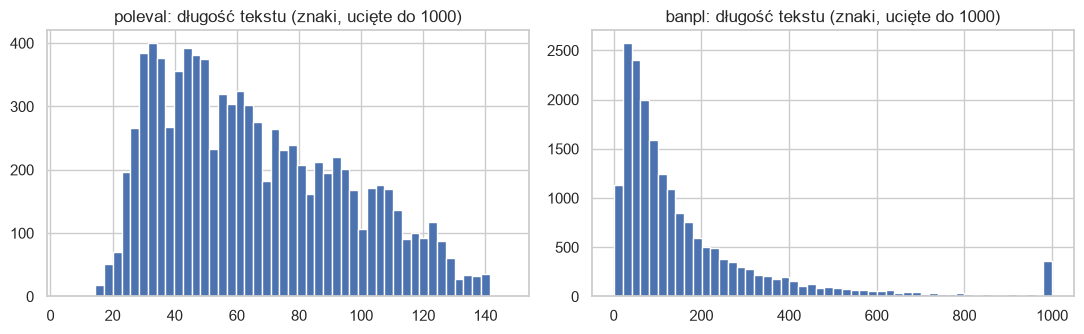

In [9]:
# kontrola wycieku: czy teksty testowe występują w treningu (dokładne duplikaty)?
for name, ds in DATASETS.items():
    leak = set(ds["test"]["text"]) & (set(ds["train"]["text"]) | set(ds["validation"]["text"]))
    print(f"{name}: duplikaty test∩train/val = {len(leak)}")
# oba zbiory na wykresie rozkładu długości
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, (name, ds) in zip(ax, DATASETS.items()):
    a.hist(ds["train"]["text"].str.len().clip(upper=1000), bins=50); a.set_title(f"{name}: długość tekstu (znaki, ucięte do 1000)")
plt.tight_layout(); plt.savefig(DIR_FIG / "datasets_text_length.png", dpi=130); plt.show()

## 5. Rejestr 10 modeli

`init_from` – skąd startuje model; `finetune_on` – na czym jest dotrenowywany (`None` = bez treningu); `random_head` – czy głowa klasyfikacyjna jest losowa (brak wiedzy o hejcie).
Gotowe modele (`herbert_plain` = HerBERT-HS, `polbert_plain` = Polbert-CB) są używane bez zmian.

In [13]:
MODEL_REGISTRY = {
    # ---- Gotowy HerBERT-HS
    "herbert_hs": dict(
        family="herbert", size="large",
        init_from=HERBERT_READY,
        finetune_on=None, random_head=False
    ),
    "herbert_hs_banpl": dict(
        family="herbert", size="large",
        init_from=HERBERT_READY,
        finetune_on="banpl", random_head=False
    ),

    # ---- Bazowy HerBERT
    "herbert_base_poleval": dict(
        family="herbert", size="large",
        init_from=HERBERT_BASE,
        finetune_on="poleval", random_head=True
    ),
    "herbert_base_banpl": dict(
        family="herbert", size="large",
        init_from=HERBERT_BASE,
        finetune_on="banpl", random_head=True
    ),

    # ---- Bazowa RoBERTa
    "roberta_base_poleval": dict(
        family="roberta", size="base",
        init_from=ROBERTA_BASE,
        finetune_on="poleval", random_head=True
    ),
    "roberta_base_banpl": dict(
        family="roberta", size="base",
        init_from=ROBERTA_BASE,
        finetune_on="banpl", random_head=True
    ),

    # ---- Gotowy Polbert-CB
    "polbert_cb": dict(
        family="polbert", size="base",
        init_from=POLBERT_READY,
        finetune_on=None, random_head=False
    ),
    "polbert_cb_banpl": dict(
        family="polbert", size="base",
        init_from=POLBERT_READY,
        finetune_on="banpl", random_head=False
    ),

    # ---- Bazowy Polbert
    "polbert_base_poleval": dict(
        family="polbert", size="base",
        init_from=POLBERT_BASE,
        finetune_on="poleval", random_head=True
    ),
    "polbert_base_banpl": dict(
        family="polbert", size="base",
        init_from=POLBERT_BASE,
        finetune_on="banpl", random_head=True
    ),
}

for k, v in MODEL_REGISTRY.items():
    v["path"] = DIR_MODELS / k

MODEL_KEYS = list(MODEL_REGISTRY)
REAL_MODEL_KEYS = MODEL_KEYS.copy()
ENSEMBLE_KEYS = MODEL_KEYS.copy()

pd.DataFrame(MODEL_REGISTRY).T[
    ["family", "size", "init_from", "finetune_on", "random_head"]
]

,family,size,init_from,finetune_on,random_head
herbert_hs,herbert,large,dkleczek/Polish-Hate-Speech-Detection-Herbert-Large,None,False
herbert_hs_banpl,herbert,large,dkleczek/Polish-Hate-Speech-Detection-Herbert-Large,banpl,False
herbert_base_poleval,herbert,large,allegro/herbert-large-cased,poleval,True
herbert_base_banpl,herbert,large,allegro/herbert-large-cased,banpl,True
roberta_base_poleval,roberta,base,sdadas/polish-roberta-base-v2,poleval,True
roberta_base_banpl,roberta,base,sdadas/polish-roberta-base-v2,banpl,True
polbert_cb,polbert,base,ptaszynski/bert-base-polish-cyberbullying,None,False
polbert_cb_banpl,polbert,base,ptaszynski/bert-base-polish-cyberbullying,banpl,False
polbert_base_poleval,polbert,base,dkleczek/bert-base-polish-uncased-v1,poleval,True
polbert_base_banpl,polbert,base,dkleczek/bert-base-polish-uncased-v1,banpl,True


## 6. Fine-tuning

Własna pętla treningowa (bez `Trainer`, żeby działała stabilnie na różnych wersjach `transformers` i na MPS):
AdamW + liniowy warmup/decay, akumulacja gradientu, przycinanie gradientu, opcjonalnie ważona strata, ewaluacja po każdej epoce na zbiorze walidacyjnym, **early stopping po macro-F1**, zapis najlepszego checkpointu (model + tokenizer + `training_info.json` + historia treningu).
Jeśli `outputs/models/<klucz>/training_info.json` istnieje, trening jest pomijany (`FORCE_RETRAIN=True` wymusza ponowny).

In [14]:
def model_is_trained(key):
    return (MODEL_REGISTRY[key]["path"] / "training_info.json").exists()

def load_tokenizer(source):
    try:
        return AutoTokenizer.from_pretrained(source)
    except Exception as e:
        if source == POLBERT_READY:        # gdyby repozytorium Polbert-CB nie miało plików tokenizera
            print('  brak tokenizera w', source, '-> używam', POLBERT_BASE, '|', str(e)[:80])
            return AutoTokenizer.from_pretrained(POLBERT_BASE)
        raise

def load_for_classification(source, random_head=False, num_labels=2):
    kw = dict(num_labels=num_labels, id2label={0: "no_hate", 1: "hate"}, label2id={"no_hate": 0, "hate": 1})
    if random_head:
        return AutoModelForSequenceClassification.from_pretrained(source, **kw)
    model = AutoModelForSequenceClassification.from_pretrained(source)       # gotowy model z własną głową
    assert model.config.num_labels == 2, f"{source}: oczekiwano 2 klas, jest {model.config.num_labels}"
    return align_head_to_hate_idx(model, source)      # po tym kroku indeks 1 = hate

class EncodedDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        enc = tokenizer(list(texts), truncation=True, max_length=max_len, padding=False)
        self.input_ids, self.attn = enc["input_ids"], enc["attention_mask"]
        self.labels = list(labels)
    def __len__(self): return len(self.labels)
    def __getitem__(self, i): return {"input_ids": self.input_ids[i], "attention_mask": self.attn[i], "labels": self.labels[i]}

def make_collate(tokenizer):
    def collate(batch):
        labels = torch.tensor([b["labels"] for b in batch])
        padded = tokenizer.pad([{"input_ids": b["input_ids"], "attention_mask": b["attention_mask"]} for b in batch], return_tensors="pt")
        return {"input_ids": padded["input_ids"], "attention_mask": padded["attention_mask"], "labels": labels}
    return collate

@torch.inference_mode()
def eval_loop(model, loader):
    model.eval(); probs, labels = [], []
    for batch in loader:
        out = model(input_ids=batch["input_ids"].to(device), attention_mask=batch["attention_mask"].to(device))
        probs.extend(torch.softmax(out.logits.float(), -1)[:, 1].cpu().tolist()); labels.extend(batch["labels"].tolist())
    return np.array(labels), np.array(probs)

def finetune(key):
    spec = MODEL_REGISTRY[key]; ds_name = spec["finetune_on"]; size = spec["size"]
    out_dir = spec["path"]; out_dir.mkdir(parents=True, exist_ok=True)
    set_seed(SEED)
    data = DATASETS[ds_name]
    train_df = data["train"]
    if MAX_TRAIN_SAMPLES.get(ds_name):
        train_df = train_df.sample(n=min(MAX_TRAIN_SAMPLES[ds_name], len(train_df)), random_state=SEED)
    val_df = data["validation"]
    print(f"\n=== FINE-TUNING {key} | start: {spec['init_from']} | dane: {ds_name} (train={len(train_df)}, val={len(val_df)}) ===")

    tok = load_tokenizer(spec["init_from"])
    model = load_for_classification(spec["init_from"], random_head=spec["random_head"])
    if GRADIENT_CHECKPOINTING and size == "large":
        model.gradient_checkpointing_enable()
        model.config.use_cache = False
    model.to(device)

    max_len = TRAIN_MAX_LEN[ds_name]
    tr_ds = EncodedDataset(train_df.text, train_df.label, tok, max_len)
    va_ds = EncodedDataset(val_df.text, val_df.label, tok, max_len)
    collate = make_collate(tok)
    tr_loader = DataLoader(tr_ds, batch_size=TRAIN_BATCH[size], shuffle=True, collate_fn=collate)
    va_loader = DataLoader(va_ds, batch_size=TRAIN_BATCH[size] * 2, shuffle=False, collate_fn=collate)

    steps_per_epoch = math.ceil(len(tr_loader) / GRAD_ACCUM[size]); total_steps = steps_per_epoch * EPOCHS
    no_decay = ["bias", "LayerNorm.weight", "layer_norm.weight"]
    params = [{"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], "weight_decay": WEIGHT_DECAY},
              {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], "weight_decay": 0.0}]
    optim = torch.optim.AdamW(params, lr=LEARNING_RATE[size])
    sched = get_linear_schedule_with_warmup(optim, int(WARMUP_RATIO * total_steps), total_steps)

    if USE_CLASS_WEIGHTS:
        counts = np.bincount(train_df.label.values, minlength=2).astype(float)
        cw = torch.tensor(counts.sum() / (2 * np.maximum(counts, 1)), dtype=torch.float32).to(device)
    else:
        cw = None
    loss_fn = torch.nn.CrossEntropyLoss(weight=cw)

    history, best_f1, bad_epochs = [], -1.0, 0
    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train(); running = 0.0; n_batches = 0
        optim.zero_grad()
        pbar = tqdm(tr_loader, desc=f"{key} epoka {epoch}/{EPOCHS}", unit="batch")
        for i, batch in enumerate(pbar, 1):
            logits = model(input_ids=batch["input_ids"].to(device), attention_mask=batch["attention_mask"].to(device)).logits
            loss = loss_fn(logits.float(), batch["labels"].to(device)) / GRAD_ACCUM[size]
            loss.backward()
            running += loss.item() * GRAD_ACCUM[size]; n_batches += 1
            if i % GRAD_ACCUM[size] == 0 or i == len(tr_loader):
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                optim.step(); sched.step(); optim.zero_grad()
            pbar.set_postfix(loss=f"{running / n_batches:.4f}")
        y_val, p_val = eval_loop(model, va_loader)
        m = binary_metrics(y_val, p_val, THRESHOLD)
        rec = {"epoch": epoch, "train_loss": running / max(n_batches, 1), "val_macro_f1": m["macro_f1"], "val_f1_hate": m["f1_hate"],
               "val_precision_hate": m["precision_hate"], "val_recall_hate": m["recall_hate"], "val_roc_auc": m["roc_auc"],
               "elapsed_min": (time.time() - t0) / 60}
        history.append(rec); print({k: round(v, 4) if isinstance(v, float) else v for k, v in rec.items()})
        if m["macro_f1"] > best_f1:
            best_f1, bad_epochs = m["macro_f1"], 0
            model.save_pretrained(out_dir); tok.save_pretrained(out_dir)          # najlepszy checkpoint
            print(f"  ↳ zapisano najlepszy model (val macro-F1={best_f1:.4f})")
        else:
            bad_epochs += 1
            if bad_epochs >= EARLY_STOP_PATIENCE:
                print("  early stopping"); break
    info = {"key": key, "init_from": spec["init_from"], "finetuned_on": ds_name, "n_train": len(train_df), "n_val": len(val_df),
            "epochs_run": len(history), "best_val_macro_f1": best_f1, "max_len_train": max_len,
            "lr": LEARNING_RATE[size], "batch": TRAIN_BATCH[size], "grad_accum": GRAD_ACCUM[size], "class_weights": USE_CLASS_WEIGHTS,
            "seed": SEED, "label_convention": "1=hate, 0=no_hate", "device": str(device), "finished": datetime.now().isoformat()}
    (out_dir / "training_history.json").write_text(json.dumps(history, indent=2))
    (out_dir / "training_info.json").write_text(json.dumps(info, indent=2))
    del model, optim, sched; free_memory()
    return history

def prepare_untuned_random_head(key):
    # zapisuje model z losową głową raz, żeby predykcje były spójne między ewaluacją a comments.csv
    spec = MODEL_REGISTRY[key]; out_dir = spec["path"]
    if (out_dir / "training_info.json").exists() and not FORCE_RETRAIN:
        return
    set_seed(SEED); out_dir.mkdir(parents=True, exist_ok=True)
    tok = load_tokenizer(spec["init_from"]); model = load_for_classification(spec["init_from"], random_head=True)
    model.save_pretrained(out_dir); tok.save_pretrained(out_dir)
    (out_dir / "training_info.json").write_text(json.dumps({"key": key, "init_from": spec["init_from"], "finetuned_on": None,
        "untuned_baseline_random_head": True, "seed": SEED, "label_convention": "1=hate, 0=no_hate"}, indent=2))
    del model; free_memory()

TRAIN_HISTORIES = {}
for key in MODEL_KEYS:
    spec = MODEL_REGISTRY[key]
    if spec["finetune_on"] is None:
        if spec["random_head"]:
            prepare_untuned_random_head(key)
        continue                                                     # herbert_plain: gotowy model z HF
    if model_is_trained(key) and not FORCE_RETRAIN:
        print(f"[pomijam] {key}: już dotrenowany ({spec['path']})")
        TRAIN_HISTORIES[key] = json.loads((spec["path"] / "training_history.json").read_text())
        continue
    TRAIN_HISTORIES[key] = finetune(key)


=== FINE-TUNING herbert_hs_banpl | start: dkleczek/Polish-Hate-Speech-Detection-Herbert-Large | dane: banpl (train=19179, val=2398) ===


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

  [dkleczek/Polish-Hate-Speech-Detection-Herbert-Large] id2label={0: 'LABEL_0', 1: 'LABEL_1'} -> indeks hate = 1 (ZAŁOŻONO 1=hate (etykiety generyczne) – zweryfikuj ROC-AUC na teście)


herbert_hs_banpl epoka 1/3:   0%|          | 0/2398 [00:00<?, ?batch/s]

{'epoch': 1, 'train_loss': 0.2611, 'val_macro_f1': 0.9249, 'val_f1_hate': 0.9268, 'val_precision_hate': 0.9048, 'val_recall_hate': 0.95, 'val_roc_auc': 0.9796, 'elapsed_min': 24.2559}


...

  ↳ zapisano najlepszy model (val macro-F1=0.9174)


polbert_base_banpl epoka 3/3:   0%|          | 0/1199 [00:00<?, ?batch/s]

{'epoch': 3, 'train_loss': 0.0375, 'val_macro_f1': 0.9224, 'val_f1_hate': 0.9226, 'val_precision_hate': 0.9218, 'val_recall_hate': 0.9233, 'val_roc_auc': 0.9695, 'elapsed_min': 22.7604}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ↳ zapisano najlepszy model (val macro-F1=0.9224)


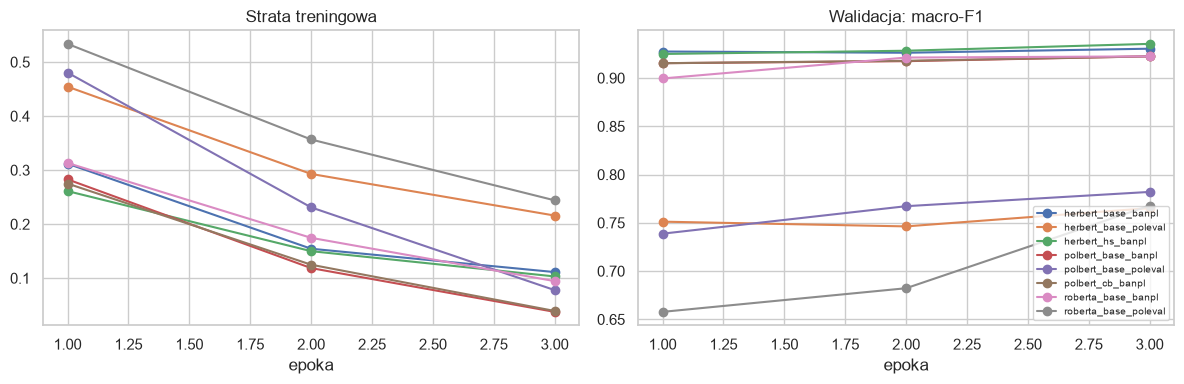

,model,epoch,train_loss,val_macro_f1,val_f1_hate,val_precision_hate,val_recall_hate,val_roc_auc,elapsed_min
0,herbert_hs_banpl,1,0.261089,0.924887,0.926829,0.904762,0.950000,0.979587,24.255880
1,herbert_hs_banpl,2,0.149916,0.928245,0.929681,0.912520,0.947500,0.980884,50.721300
2,herbert_hs_banpl,3,0.103130,0.935357,0.935977,0.927928,0.944167,0.979971,75.079380
3,herbert_base_poleval,1,0.454409,0.751201,0.551020,0.486486,0.635294,0.912277,4.726350
4,herbert_base_poleval,2,0.292876,0.746294,0.545455,0.459677,0.670588,0.925119,9.426641
5,herbert_base_poleval,3,0.215821,0.765232,0.574468,0.524272,0.635294,0.924337,14.126823
6,herbert_base_banpl,1,0.311857,0.927432,0.928159,0.919804,0.936667,0.979433,24.097058
7,herbert_base_banpl,2,0.154411,0.926152,0.927785,0.908873,0.947500,0.982292,48.162355
8,herbert_base_banpl,3,0.111193,0.930350,0.931134,0.921633,0.940833,0.981951,72.462895
9,roberta_base_poleval,1,0.533626,0.657760,0.360902,0.500000,0.282353,0.845880,1.379426


In [15]:
# krzywe uczenia z wszystkich dotrenowanych modeli
rows = [dict(model=k, **h) for k, hist in TRAIN_HISTORIES.items() for h in hist]
if rows:
    th = pd.DataFrame(rows); th.to_csv(OUT / "training_histories_all.csv", index=False)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for k, g in th.groupby("model"):
        ax[0].plot(g["epoch"], g["train_loss"], marker="o", label=k); ax[1].plot(g["epoch"], g["val_macro_f1"], marker="o", label=k)
    ax[0].set_title("Strata treningowa"); ax[1].set_title("Walidacja: macro-F1")
    for a in ax: a.set_xlabel("epoka")
    ax[1].legend(fontsize=7); plt.tight_layout(); plt.savefig(DIR_FIG / "training_curves.png", dpi=130); plt.show()
    display(th)

## 7. Silnik inferencji

Wspólny dla ewaluacji i `comments.csv`. Długie teksty są dzielone na okna (do 512 tokenów, z nakładką), a wynik to **maksimum P(hate) po oknach**. Zwraca `p_hate`, `p_no_hate`, `n_chunks`.

In [16]:
def resolve_model_source(key):
    spec = MODEL_REGISTRY[key]
    if (spec["path"] / "training_info.json").exists() and (spec["path"] / "config.json").exists():
        return str(spec["path"])
    assert spec["finetune_on"] is None and not spec["random_head"], f"Model {key} nie jest jeszcze dotrenowany – uruchom sekcję 6."
    return spec["init_from"]

def load_model_for_inference(key):
    src = resolve_model_source(key)
    tok = load_tokenizer(src)
    model = AutoModelForSequenceClassification.from_pretrained(src)
    assert model.config.num_labels == 2
    align_head_to_hate_idx(model, src)
    if device.type == "cuda":
        model.half()
    model.to(device).eval()
    return model, tok

@torch.inference_mode()
def _score_batch(model, tok, texts):
    if tok.is_fast:
        enc = tok(texts, truncation=True, max_length=INFER_MAX_LEN, stride=INFER_STRIDE, return_overflowing_tokens=True, padding=False)
        mapping = enc["overflow_to_sample_mapping"]
    else:                                   # tokenizer wolny: bez okien, zwykłe ucięcie do max_length
        enc = tok(texts, truncation=True, max_length=INFER_MAX_LEN, padding=False)
        mapping = list(range(len(texts)))
    feats = [{"input_ids": enc["input_ids"][k], "attention_mask": enc["attention_mask"][k]} for k in range(len(mapping))]
    chunk_p = []
    for s in range(0, len(feats), INFER_CHUNK_BATCH):
        padded = tok.pad(feats[s:s + INFER_CHUNK_BATCH], return_tensors="pt")
        padded = {k: v.to(device) for k, v in padded.items() if k in ("input_ids", "attention_mask")}
        logits = model(**padded).logits.float()
        chunk_p.extend(torch.softmax(logits, -1)[:, 1].cpu().tolist())          # klasa 1 = hate
    scores, n_chunks = [0.0] * len(texts), [0] * len(texts)
    for p, si in zip(chunk_p, mapping):
        scores[si] = max(scores[si], p); n_chunks[si] += 1
    return scores, n_chunks

def predict_texts(model, tok, texts, desc="predykcje"):
    texts = list(texts)
    uniq = list(dict.fromkeys(t for t in texts if t))
    uniq.sort(key=len)
    cache = {}
    for s in tqdm(range(0, len(uniq), INFER_BATCH), desc=desc, unit="batch"):
        batch = uniq[s:s + INFER_BATCH]
        sc, nc = _score_batch(model, tok, batch)
        cache.update({t: (a, b) for t, a, b in zip(batch, sc, nc)})
    p = np.array([cache[t][0] if t in cache else np.nan for t in texts])
    n = np.array([cache[t][1] if t in cache else 0 for t in texts])
    return p, n

## 8. Ewaluacja: 10 modeli × 2 zbiory testowe = 20 ewaluacji

Metryki: accuracy, precision/recall/F1 dla klasy hate, macro-F1, MCC, Cohen κ, ROC-AUC, PR-AUC, Brier, ECE + 95% przedział ufności (bootstrap) dla macro-F1 i F1(hate). Predykcje każdego przykładu zapisywane są do `outputs/evaluation/<model>/<zbiór>/predictions.csv`.

In [17]:
def eval_paths(key, ds_name):
    d = DIR_EVAL / key / ds_name; d.mkdir(parents=True, exist_ok=True)
    return d / "predictions.csv", d / "metrics.json"

EVAL_ROWS = []
for key in MODEL_KEYS:
    todo = [ds for ds in DATASETS if FORCE_REEVAL or not eval_paths(key, ds)[1].exists()]
    model = tok = None
    if todo:
        model, tok = load_model_for_inference(key)
    for ds_name in DATASETS:
        pred_path, met_path = eval_paths(key, ds_name)
        if ds_name in todo:
            test = DATASETS[ds_name]["test"]
            p, n = predict_texts(model, tok, test.text, desc=f"{key} -> test {ds_name}")
            y = test.label.values
            m = binary_metrics(y, p, THRESHOLD)
            yhat = (p >= THRESHOLD).astype(int)
            for metric in ["macro_f1", "f1_hate"]:
                lo, hi = bootstrap_ci(y, yhat, metric, n_boot=BOOTSTRAP_N)
                m[f"{metric}_ci_low"], m[f"{metric}_ci_high"] = lo, hi
            m.update({"model": key, "test_set": ds_name, "threshold": THRESHOLD})
            pd.DataFrame({"text": test.text, "true_label": y, "p_hate": p, "p_no_hate": 1 - p, "pred_label": yhat,
                          "confidence": np.maximum(p, 1 - p), "correct": (yhat == y).astype(int), "n_chunks": n}).to_csv(pred_path, index=False)
            met_path.write_text(json.dumps(m, indent=2))
        EVAL_ROWS.append(json.loads(met_path.read_text()))
    if model is not None:
        del model, tok; free_memory()

EVAL = pd.DataFrame(EVAL_ROWS)
EVAL.to_csv(DIR_EVAL / "evaluation_all_20.csv", index=False)
show = ["model", "test_set", "n", "accuracy", "precision_hate", "recall_hate", "f1_hate", "macro_f1", "mcc", "roc_auc", "pr_auc", "ece"]
EVAL[show].round(3)

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

  [dkleczek/Polish-Hate-Speech-Detection-Herbert-Large] id2label={0: 'LABEL_0', 1: 'LABEL_1'} -> indeks hate = 1 (ZAŁOŻONO 1=hate (etykiety generyczne) – zweryfikuj ROC-AUC na teście)


herbert_hs -> test poleval:   0%|          | 0/63 [00:00<?, ?batch/s]

herbert_hs -> test banpl:   0%|          | 0/150 [00:00<?, ?batch/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  [outputs/models/polbert_base_banpl] id2label={0: 'no_hate', 1: 'hate'} -> indeks hate = 1 (z nazw etykiet)


polbert_base_banpl -> test poleval:   0%|          | 0/63 [00:00<?, ?batch/s]

polbert_base_banpl -> test banpl:   0%|          | 0/150 [00:00<?, ?batch/s]

,model,test_set,n,accuracy,precision_hate,recall_hate,f1_hate,macro_f1,mcc,roc_auc,pr_auc,ece
0,herbert_hs,poleval,1000,0.881,0.543,0.709,0.615,0.772,0.553,0.892,0.590,0.083
1,herbert_hs,banpl,2398,0.807,0.792,0.832,0.811,0.806,0.614,0.885,0.882,0.029
2,herbert_hs_banpl,poleval,1000,0.877,0.541,0.545,0.543,0.736,0.472,0.805,0.499,0.099
3,herbert_hs_banpl,banpl,2398,0.937,0.927,0.949,0.938,0.937,0.875,0.983,0.983,0.050
4,herbert_base_poleval,poleval,1000,0.918,0.750,0.582,0.655,0.804,0.616,0.900,0.697,0.061
5,herbert_base_poleval,banpl,2398,0.751,0.823,0.640,0.720,0.748,0.515,0.823,0.833,0.176
6,herbert_base_banpl,poleval,1000,0.889,0.589,0.567,0.578,0.757,0.514,0.812,0.552,0.094
7,herbert_base_banpl,banpl,2398,0.930,0.916,0.947,0.931,0.930,0.860,0.984,0.984,0.052
8,roberta_base_poleval,poleval,1000,0.912,0.730,0.545,0.624,0.787,0.583,0.900,0.684,0.061
9,roberta_base_poleval,banpl,2398,0.709,0.862,0.499,0.632,0.696,0.462,0.777,0.813,0.240


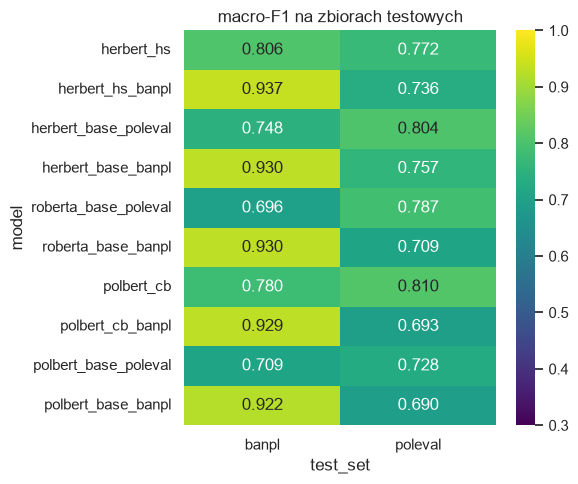

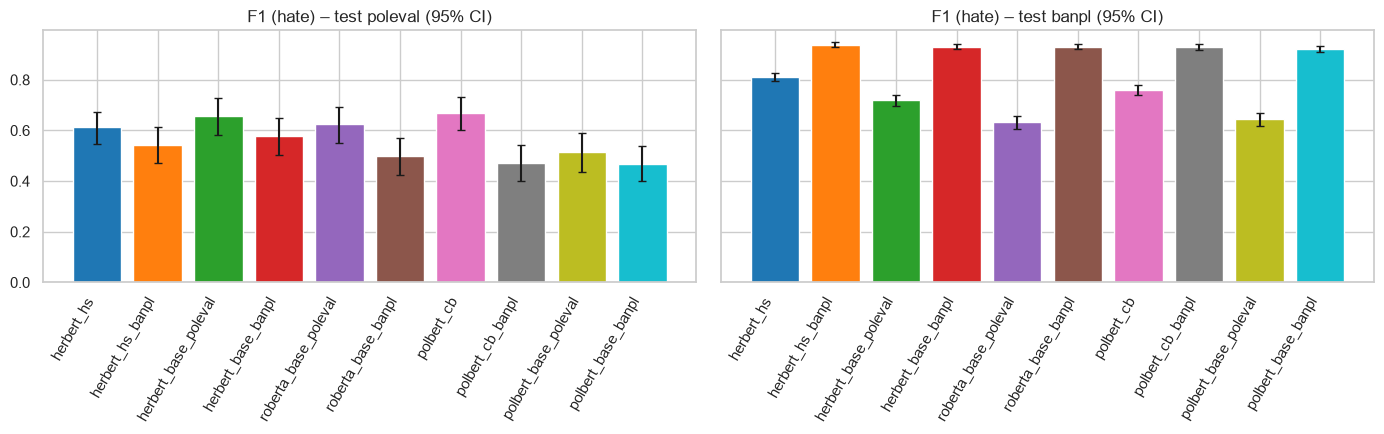

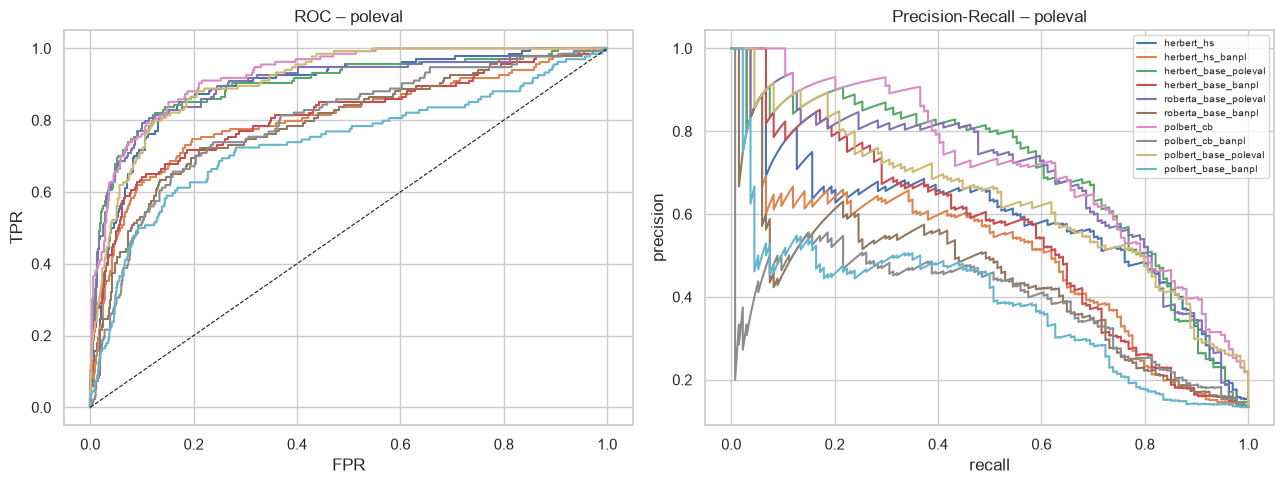

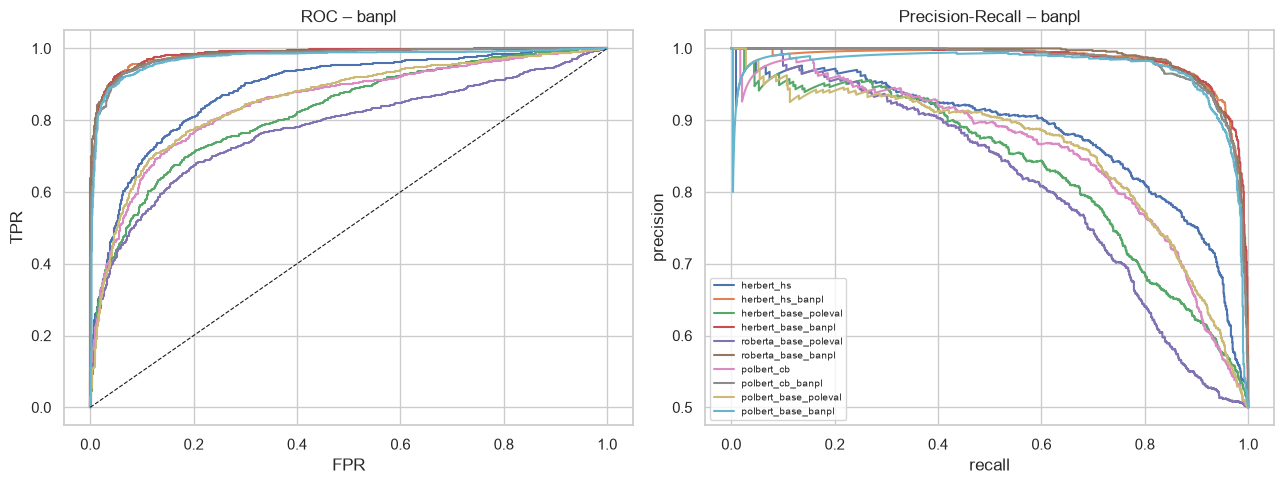

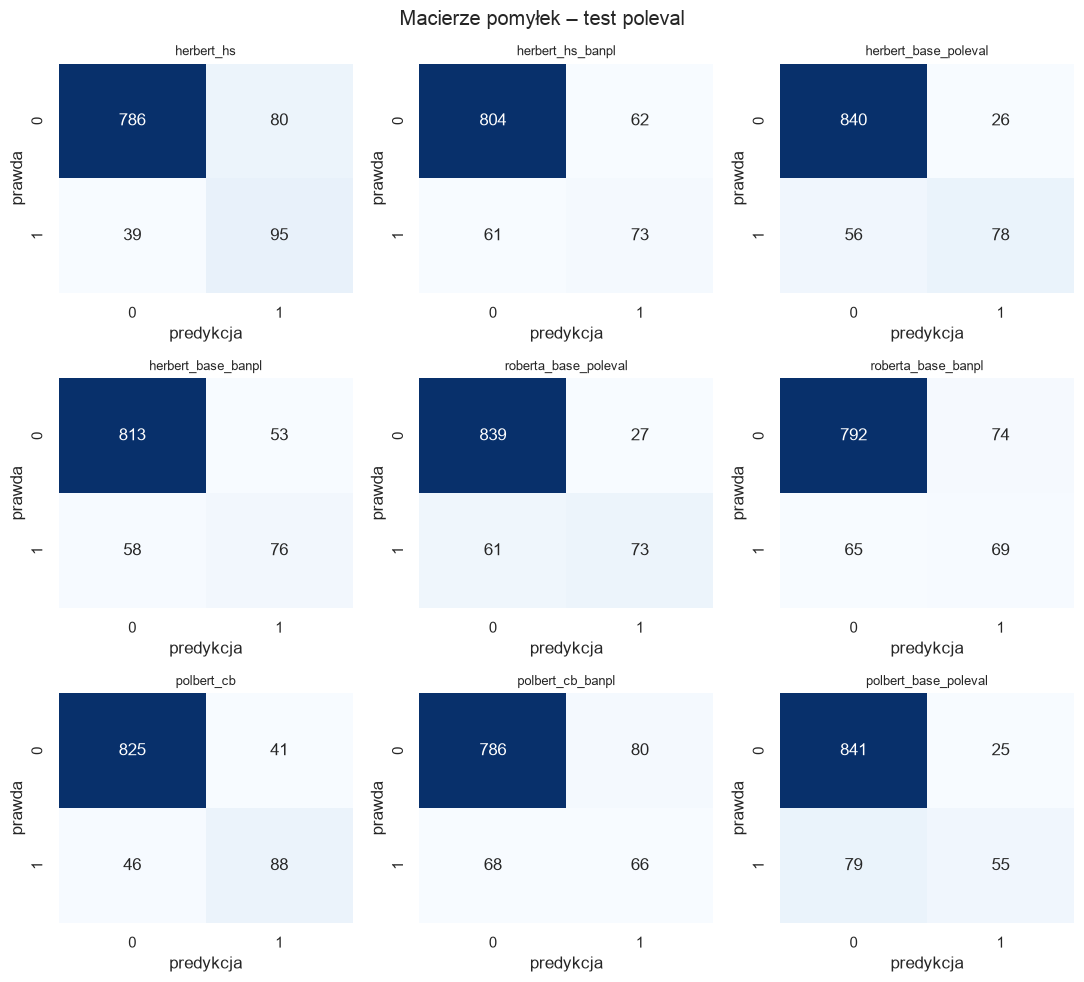

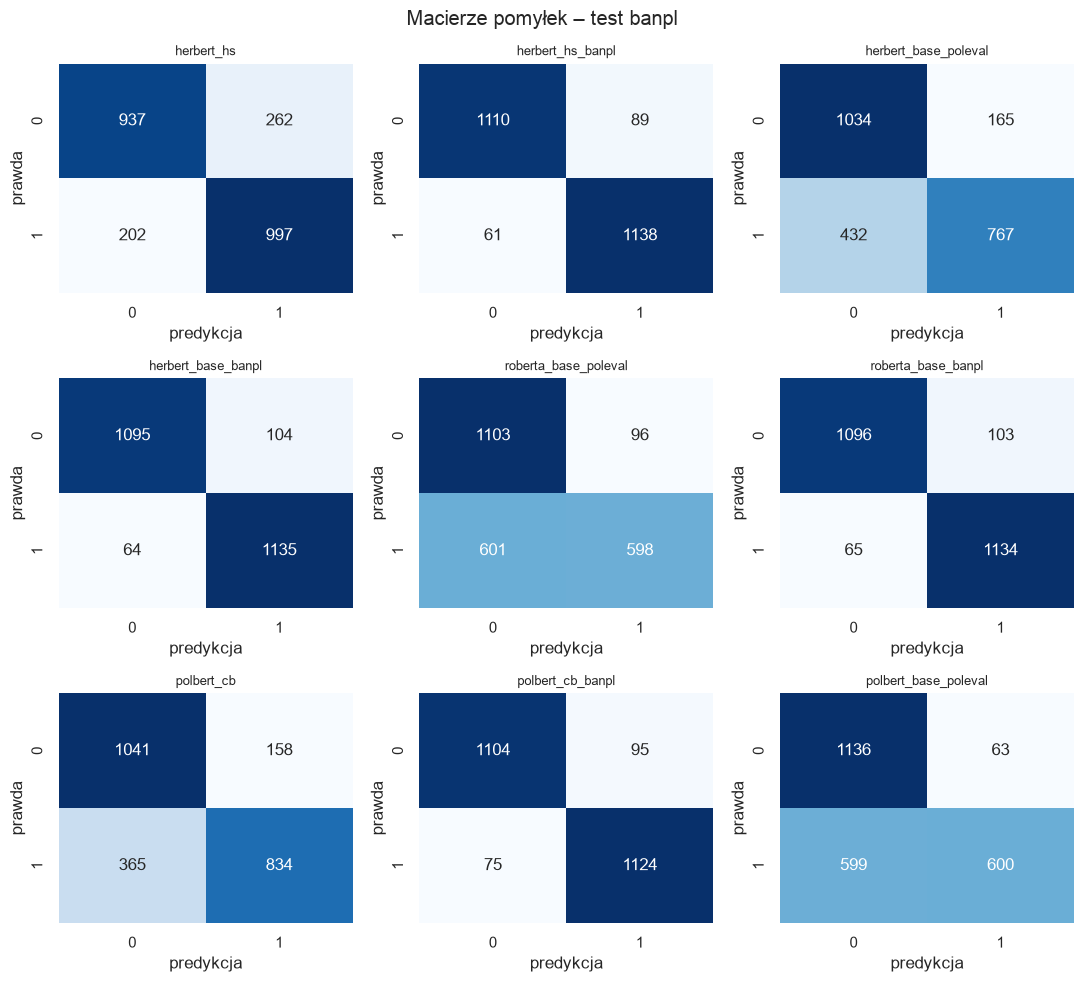

In [18]:
# --- wizualizacje ewaluacji
piv = EVAL.pivot(index="model", columns="test_set", values="macro_f1").reindex(MODEL_KEYS)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", vmin=0.3, vmax=1.0, ax=ax); ax.set_title("macro-F1 na zbiorach testowych")
plt.tight_layout(); plt.savefig(DIR_FIG / "eval_macroF1_heatmap.png", dpi=130); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, ds_name in zip(axes, DATASETS):
    g = EVAL[EVAL.test_set == ds_name].set_index("model").reindex(MODEL_KEYS)
    err = np.vstack([g.f1_hate - g.f1_hate_ci_low, g.f1_hate_ci_high - g.f1_hate])
    ax.bar(range(len(g)), g.f1_hate, yerr=err, capsize=3, color=sns.color_palette("tab10", len(g)))
    ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index, rotation=60, ha="right"); ax.set_title(f"F1 (hate) – test {ds_name} (95% CI)")
plt.tight_layout(); plt.savefig(DIR_FIG / "eval_f1_hate_bars.png", dpi=130); plt.show()

for ds_name in DATASETS:
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    for key in MODEL_KEYS:
        d = pd.read_csv(eval_paths(key, ds_name)[0])
        if d.true_label.nunique() < 2: continue
        fpr, tpr, _ = roc_curve(d.true_label, d.p_hate); ax[0].plot(fpr, tpr, label=key)
        pr, rc, _ = precision_recall_curve(d.true_label, d.p_hate); ax[1].plot(rc, pr, label=key)
    ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_title(f"ROC – {ds_name}"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR")
    ax[1].set_title(f"Precision-Recall – {ds_name}"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(DIR_FIG / f"eval_roc_pr_{ds_name}.png", dpi=130); plt.show()

for ds_name in DATASETS:
    fig, axes = plt.subplots(3, 3, figsize=(11, 10))
    for ax, key in zip(axes.ravel(), MODEL_KEYS):
        d = pd.read_csv(eval_paths(key, ds_name)[0])
        cm = pd.crosstab(d.true_label, d.pred_label).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax); ax.set_title(key, fontsize=9)
        ax.set_xlabel("predykcja"); ax.set_ylabel("prawda")
    plt.suptitle(f"Macierze pomyłek – test {ds_name}"); plt.tight_layout(); plt.savefig(DIR_FIG / f"eval_confusion_{ds_name}.png", dpi=130); plt.show()

In [20]:
# kontrola poprawności: model z AUC < 0.5 na teście może mieć odwróconą konwencję etykiet
for _, r in EVAL.iterrows():
    if r["roc_auc"] < 0.5 and not MODEL_REGISTRY[r["model"]]["is_untuned_baseline"]:
        print(f"UWAGA: {r['model']} na {r['test_set']}: ROC-AUC={r['roc_auc']:.3f} < 0.5 – sprawdź kolejność klas (HATE_INDEX_OVERRIDE w konfiguracji), potem FORCE_REEVAL=True.")
print("Modele nietrenowane (losowa głowa) powinny mieć AUC ≈ 0.5:")

Modele nietrenowane (losowa głowa) powinny mieć AUC ≈ 0.5:


## 9. Predykcje na `comments.csv` (osobno dla każdego modelu)

Dla każdego komentarza zapisywane są: `p_hate`, `p_no_hate`, `pred_label` (1/0), `confidence` (= max z dwóch prawdopodobieństw), `logit_hate`, `uncertain` (blisko progu), `n_chunks`. Pliki: `outputs/comments_predictions/<model>.csv` + zbiorczy `all_models_wide.csv`.

In [21]:
def pred_file(key): return DIR_PRED / f"{key}.csv"

for key in MODEL_KEYS:
    if pred_file(key).exists() and not FORCE_REPREDICT:
        print(f"[pomijam] {key}: predykcje już istnieją"); continue
    model, tok = load_model_for_inference(key)
    p, n = predict_texts(model, tok, df.comment_text_model, desc=f"{key} -> comments")
    out = df[["comment_id", "video_id", "comment_date", "comment_text", "comment_text_model", "like_count", "is_reply"]].copy()
    out["p_hate"] = p; out["p_no_hate"] = 1 - p
    out["pred_label"] = np.where(np.isnan(p), -1, (p >= THRESHOLD).astype(int))        # -1 = pusty komentarz
    out["pred_name"] = out["pred_label"].map({1: "hate", 0: "no_hate", -1: "empty"})
    out["confidence"] = np.maximum(p, 1 - p)
    pc = np.clip(p, 1e-6, 1 - 1e-6); out["logit_hate"] = np.log(pc / (1 - pc))
    out["uncertain"] = (np.abs(p - 0.5) < UNCERTAIN_BAND).astype(int)
    out["n_chunks"] = n; out["model"] = key; out["threshold"] = THRESHOLD
    out.to_csv(pred_file(key), index=False, encoding="utf-8-sig")
    del model, tok; free_memory()

PRED = {k: pd.read_csv(pred_file(k)) for k in MODEL_KEYS}
wide = df[["comment_id", "video_id", "comment_text", "comment_text_model"]].copy()
for k in MODEL_KEYS:
    wide[f"p_{k}"] = PRED[k]["p_hate"].values; wide[f"y_{k}"] = PRED[k]["pred_label"].values
ens_keys = ENSEMBLE_KEYS
wide["n_models_hate"] = wide[[f"y_{k}" for k in ens_keys]].eq(1).sum(axis=1)
wide["share_models_hate"] = wide["n_models_hate"] / len(ens_keys)
wide["mean_p_hate_ensemble"] = wide[[f"p_{k}" for k in ens_keys]].mean(axis=1)
wide["ensemble_majority"] = (wide["share_models_hate"] > 0.5).astype(int)
wide.to_csv(DIR_PRED / "all_models_wide.csv", index=False, encoding="utf-8-sig")
print("Zapisano:", DIR_PRED / "all_models_wide.csv", "| modele w ensemble:", ens_keys)

summ = pd.DataFrame({k: {"hate": int((PRED[k].pred_label == 1).sum()), "no_hate": int((PRED[k].pred_label == 0).sum()),
                         "% hate": round(100 * (PRED[k].pred_label == 1).sum() / max((PRED[k].pred_label >= 0).sum(), 1), 2),
                         "mean_p_hate": round(PRED[k].p_hate.mean(), 4), "uncertain": int(PRED[k].uncertain.sum()),
                         "chunked(>1)": int((PRED[k].n_chunks > 1).sum())} for k in MODEL_KEYS}).T
summ.to_csv(DIR_PRED / "summary_per_model.csv"); summ

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

  [dkleczek/Polish-Hate-Speech-Detection-Herbert-Large] id2label={0: 'LABEL_0', 1: 'LABEL_1'} -> indeks hate = 1 (ZAŁOŻONO 1=hate (etykiety generyczne) – zweryfikuj ROC-AUC na teście)


herbert_hs -> comments:   0%|          | 0/1714 [00:00<?, ?batch/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

  [outputs/models/herbert_hs_banpl] id2label={0: 'no_hate', 1: 'hate'} -> indeks hate = 1 (z nazw etykiet)


...

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  [outputs/models/polbert_base_banpl] id2label={0: 'no_hate', 1: 'hate'} -> indeks hate = 1 (z nazw etykiet)


polbert_base_banpl -> comments:   0%|          | 0/1714 [00:00<?, ?batch/s]

Zapisano: outputs/comments_predictions/all_models_wide.csv | modele w ensemble: ['herbert_hs', 'herbert_hs_banpl', 'herbert_base_poleval', 'herbert_base_banpl', 'roberta_base_poleval', 'roberta_base_banpl', 'polbert_cb', 'polbert_cb_banpl', 'polbert_base_poleval', 'polbert_base_banpl']


,hate,no_hate,% hate,mean_p_hate,uncertain,chunked(>1)
herbert_hs,11082.0,16443.0,40.26,0.4102,4134.0,188.0
herbert_hs_banpl,4261.0,23264.0,15.48,0.1615,745.0,188.0
herbert_base_poleval,6402.0,21123.0,23.26,0.2510,1756.0,188.0
herbert_base_banpl,4476.0,23049.0,16.26,0.1679,650.0,188.0
roberta_base_poleval,3198.0,24327.0,11.62,0.1457,728.0,193.0
roberta_base_banpl,4447.0,23078.0,16.16,0.1655,470.0,193.0
polbert_cb,4074.0,23451.0,14.80,0.1736,589.0,212.0
polbert_cb_banpl,3854.0,23671.0,14.00,0.1436,341.0,212.0
polbert_base_poleval,2714.0,24811.0,9.86,0.1036,322.0,212.0
polbert_base_banpl,3638.0,23887.0,13.22,0.1341,344.0,212.0


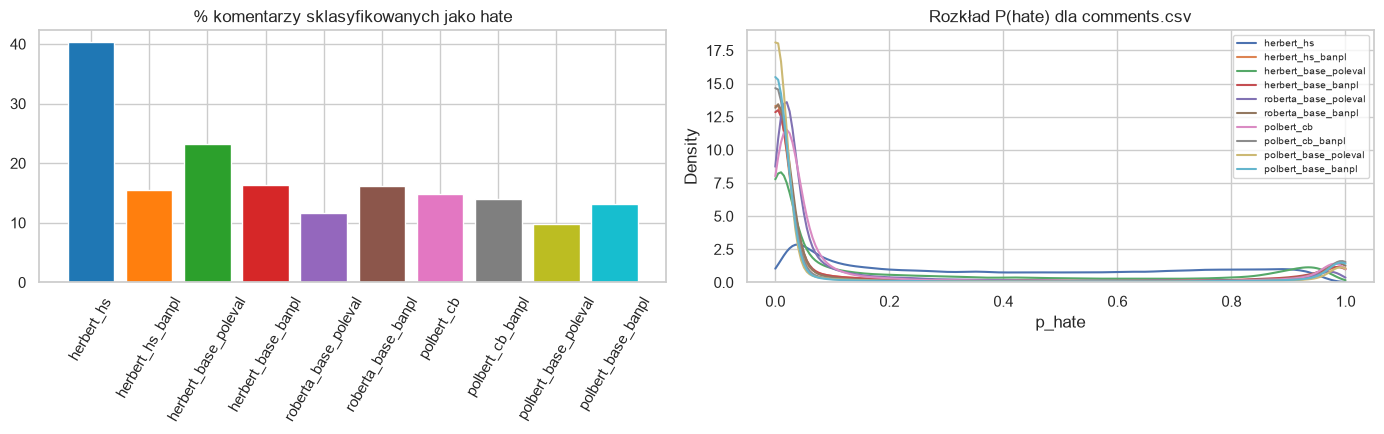

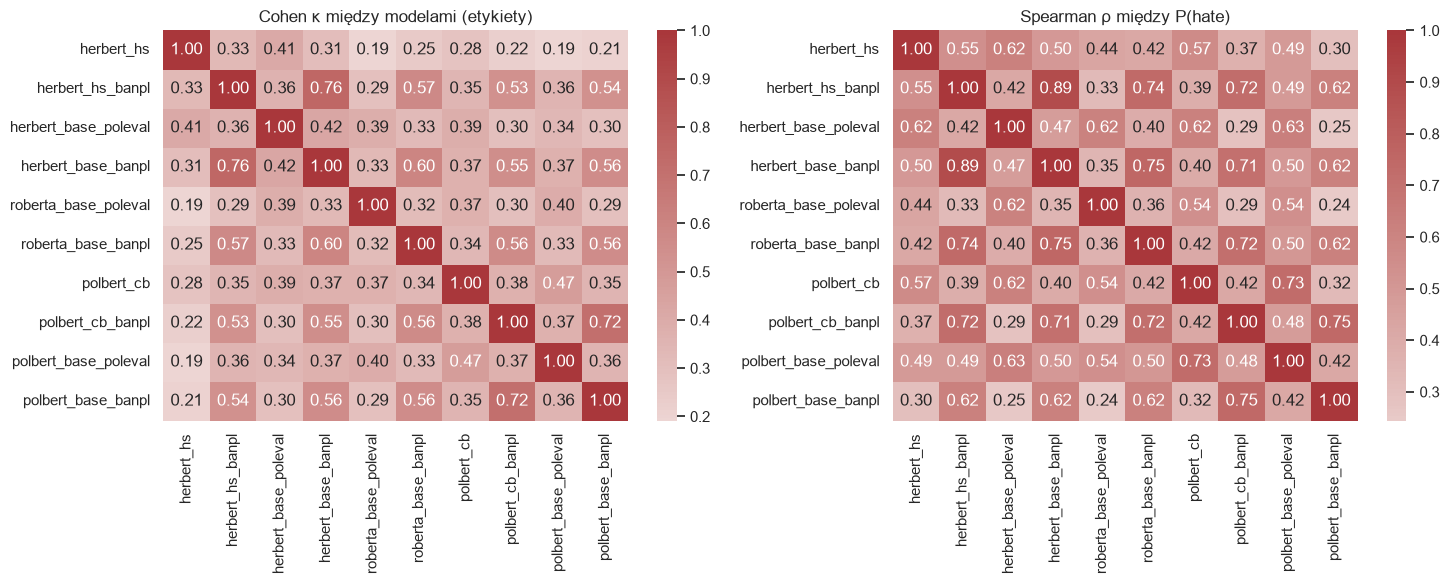

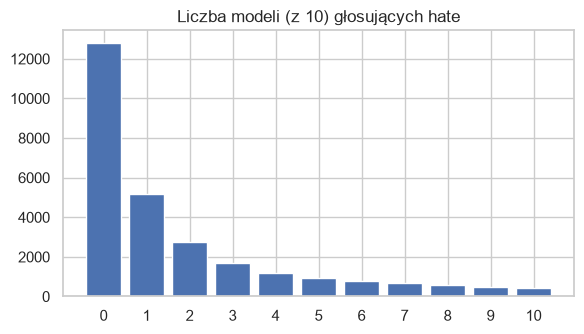

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(summ.index, summ["% hate"], color=sns.color_palette("tab10", len(summ))); ax[0].set_title("% komentarzy sklasyfikowanych jako hate")
ax[0].tick_params(axis="x", rotation=60)
for k in MODEL_KEYS:
    sns.kdeplot(PRED[k].p_hate.dropna(), ax=ax[1], label=k, bw_adjust=0.5, clip=(0, 1))
ax[1].set_title("Rozkład P(hate) dla comments.csv"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(DIR_FIG / "comments_hate_share_and_dist.png", dpi=130); plt.show()

# zgodność między modelami: kappa Cohena na etykietach + Spearman na prawdopodobieństwach
Y = wide[[f"y_{k}" for k in MODEL_KEYS]].replace(-1, np.nan); Y.columns = MODEL_KEYS
P = wide[[f"p_{k}" for k in MODEL_KEYS]]; P.columns = MODEL_KEYS
kappa_models, pct_models, _, _ = pairwise_agreement(Y)
spear = P.corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(kappa_models.astype(float), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax[0]); ax[0].set_title("Cohen κ między modelami (etykiety)")
sns.heatmap(spear, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax[1]); ax[1].set_title("Spearman ρ między P(hate)")
plt.tight_layout(); plt.savefig(DIR_FIG / "comments_model_agreement.png", dpi=130); plt.show()
kappa_models.to_csv(DIR_PRED / "model_pairwise_kappa.csv"); spear.to_csv(DIR_PRED / "model_pairwise_spearman.csv")

# ile modeli głosuje hate
vc = wide["n_models_hate"].value_counts().sort_index()
plt.figure(figsize=(6, 3.5)); plt.bar(vc.index.astype(str), vc.values); plt.title(f"Liczba modeli (z {len(ens_keys)}) głosujących hate"); plt.tight_layout()
plt.savefig(DIR_FIG / "comments_votes_distribution.png", dpi=130); plt.show()

In [23]:
# komentarze, co do których modele najbardziej się różnią + najbardziej "hejtowe" wg ensemble
wide["p_std"] = wide[[f"p_{k}" for k in ens_keys]].std(axis=1)
print("Największa niezgoda modeli:")
display(wide.sort_values("p_std", ascending=False)[["comment_text", "n_models_hate", "mean_p_hate_ensemble", "p_std"]].head(10))
print("Najwyższe średnie P(hate) w ensemble:")
display(wide.sort_values("mean_p_hate_ensemble", ascending=False)[["comment_text", "n_models_hate", "mean_p_hate_ensemble"]].head(10))
# hate per film
pv = wide.assign(h=wide["ensemble_majority"]).groupby("video_id").agg(n=("comment_id", "count"), hate_majority=("h", "sum"),
                                                                       mean_p=("mean_p_hate_ensemble", "mean"))
pv["share"] = pv.hate_majority / pv.n; pv.sort_values("share", ascending=False).to_csv(DIR_PRED / "hate_per_video.csv"); pv.sort_values("share", ascending=False).head(10)

Największa niezgoda modeli:


,comment_text,n_models_hate,mean_p_hate_ensemble,p_std
24143,Yebac ukraincow,5,0.510350,0.515729
23733,Ukraina ma ruch bezwizowy z krajami Unii Europejskiej (oraz strefy Schengen) od 11 czerwca 2017 roku wystarczy sprawdzić info a nie pierdolić głupoty,5,0.511925,0.513643
23964,Dedykuję walczącej Ukrainie moją autorską piosenkę\n\nIDI NA CHUJ vocal version / nowak691\nhttps://www.youtube.com/watch?v=XWdDto8_l1U,5,0.511999,0.513402
660,Gdyby ktoś zechciał wesprzeć biedne zwierzęta na Ukrainie w tym trudnym czasie:\r\nhttps://pomagam.pl/beopw5zj\r\nDziękujemy za każdy gest! ❤,5,0.503323,0.512819
25341,Kolego byłem pięć lat w Legii cudzoziemskiej tak o wojnie t9 mi nie pierdol na Ukrainie autobus się nazywa marszruta i to au ogulnie t sa zulte,5,0.514336,0.511459
26490,Wszystko ładnie pięknie tylko wyjebane mam w ta Ukrainę xD \nAle doceniam Twoja pracę 😅,5,0.519025,0.508417
702,Następny mądrala zaszczepiony przez SBU…To już ukraińskie media są bardziej wiarygodne od tego czarno-czerwonego lokaja…,5,0.481489,0.506745
5482,"4:06 Polska z niczego nie zrezygnowała z własnej woli, poprostu Piłsudski dostał wpierdol pod Kijowem i musiał stamtąd uciekać.",5,0.515472,0.505293
12111,Relacja polsko ukraińska jest nie do ogarnięcia a raczej pojebana-sam mam rodzine pod Tarnopolem .Jak by to powiedzieć ...delikatnie nie ufam i ni...,5,0.522146,0.505182
6274,Bezczelna arogancja Ukraińców dorównuje tylko oderwaniu od rzeczywistości zdrajców rządzących Polską.,5,0.483689,0.505181


Najwyższe średnie P(hate) w ensemble:


,comment_text,n_models_hate,mean_p_hate_ensemble
8421,"Kolejny ukrainski dupowłaz, pierdolony frajer",10,0.992050
25537,Precz z kurwami ukraińskimi do domu!!!,10,0.991518
19039,"Kurwa prawda jest taka że to Polacy w dupę wchodzą Ukraińcy , kurwa hańba , naród cioty teraz i zdrajców ojczyzny , co kurwy zrobili z Polską",10,0.991516
894,Spierdalaj złodzieju czekamy na was za Wolyn\n Bydlaku😊😅😮,10,0.991304
10929,jebać kurwe ukraine jebać rzydowska cenzure pedofilskiego fejsbuka,10,0.991142
8990,"Pierdolicie zelenski to cpun i odpad ludzki, krętacz zlodziej i prymityw. Precz z upadlincom, zabieraj swoich ukrow i wypierdalaj do siebie bande...",10,0.991094
1819,"😂😂😂😂ty ukrainski propagandzisto , apotkam to zajebie na łeb, ścierwo",10,0.991057
21832,kojowska onuco wypad z kanału zero dziwko ukraińska!!!!,10,0.990843
9036,Won ukraińskie ścierwo z Polski,10,0.990698
1624,Ukraińskie gówna won z Polski\nSmierdziuchy ukraińskie gówna,10,0.990438


,n,hate_majority,mean_p,share
video_id,,,,
SfJDxqoaRoM,2,2,0.703657,1.000000
7JAtp_HeeyU,1,1,0.970351,1.000000
TRwXZUl1l3I,1,1,0.550413,1.000000
XJQU2eji_ao,1,1,0.989935,1.000000
GYBDKSJhNrg,1,1,0.653096,1.000000
6_Ymj_TAP2I,1,1,0.819823,1.000000
U5Lh8aGOCrI,1,1,0.813962,1.000000
dWlF4v2A5YE,8,6,0.702834,0.750000
WCUvkj1Yv28,4,3,0.550824,0.750000


## 10. Próbka do adnotacji (4 adnotatorów)

- Próbka jest **warstwowana** wg liczby modeli głosujących „hate” (hejt jest rzadki, więc losowa próbka miałaby prawie same zera). Każda warstwa daje `ANN_N_PER_STRATUM` komentarzy.
- Zapisywane są **wagi próbkowania** (`sampling_weight` = rozmiar warstwy / liczba wylosowanych), dzięki którym później można policzyć metryki ważone, odzwierciedlające całą populację komentarzy.
- Wszyscy 4 adnotatorzy oceniają **te same** komentarze (konieczne do współczynników zgodności), ale w **innej, losowej kolejności**, bez widoku predykcji modeli.
- Każdy adnotator dostaje własny plik CSV i XLSX (z listą rozwijaną 0/1). Wypełnione pliki wrzuć do `outputs/annotation/completed/` (nazwy: `annotator_A1.csv/xlsx` itd.).

Etykieta: **1 = hate, 0 = no hate**; puste = nie da się ocenić (zostanie potraktowane jako brak oceny).

In [26]:
GUIDELINES = '''# Instrukcja adnotacji

Dla każdego komentarza wpisz w kolumnie `label`:

- **1 = hate** – komentarz atakuje lub używa pejoratywnego/dyskryminującego języka wobec osoby lub grupy ze względu na to, kim są
  (religia, narodowość, pochodzenie etniczne, rasa, płeć, orientacja, niepełnosprawność itp.) albo nawołuje do przemocy/nienawiści wobec nich.
- **0 = no hate** – wszystko inne, także: krytyka polityków/działań/armii/państwa jako instytucji, ostre opinie bez stygmatyzacji grupy,
  przekleństwa nieskierowane przeciwko grupie, informowanie o wojnie/przemocy, ironia nieobejmująca grupy.
- **puste** – naprawdę nie da się ocenić (np. sam emoji/link, brak kontekstu). Używaj rzadko.

Zasady:
1. Oceniaj sam tekst komentarza (bez zgadywania kontekstu filmu).
2. Nie konsultuj się z innymi adnotatorami i nie sprawdzaj predykcji modeli.
3. W razie wątpliwości wpisz swoją najlepszą ocenę i opisz problem w kolumnie `note`.
4. Wątpliwe przypadki zostaną omówione dopiero PO zebraniu wszystkich ocen (adjudykacja remisów 2:2).
'''
(DIR_ANN / "ANNOTATION_GUIDELINES.md").write_text(GUIDELINES, encoding="utf-8")

master_path = DIR_ANN / "annotation_master.csv"
if master_path.exists():
    master = pd.read_csv(master_path)
    print(f"Wczytano istniejącą próbkę ({len(master)}) – nie losuję ponownie, żeby nie rozjechać adnotacji.")
else:
    pool = wide[(wide.comment_text_model.str.len() >= ANN_MIN_CHARS)].copy()
    share = pool["share_models_hate"]
    pool["stratum"] = np.select([share == 0, share <= 1/3, share <= 2/3, share < 1, share == 1],
                                ["S0_none", "S1_few", "S2_half", "S3_most", "S4_all"], default="S0_none")
    sizes = pool["stratum"].value_counts().to_dict()
    parts = []
    for s, g in pool.groupby("stratum"):
        k = min(ANN_N_PER_STRATUM, len(g))
        sm = g.sample(n=k, random_state=SEED).copy(); sm["stratum_size"] = len(g); sm["sampling_weight"] = len(g) / k
        parts.append(sm)
    master = pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
    master.insert(0, "item_id", [f"item_{i:04d}" for i in range(len(master))])
    master = master.merge(df[["comment_id", "comment_date", "like_count", "is_reply"]], on="comment_id", how="left")
    master.to_csv(master_path, index=False, encoding="utf-8-sig")
print("Rozmiar populacji w warstwach:", pool["stratum"].value_counts().sort_index().to_dict() if 'pool' in globals() else "")
print("Rozmiar próbki:", len(master)); master["stratum"].value_counts().sort_index()

Rozmiar populacji w warstwach: {'S0_none': 12792, 'S1_few': 9645, 'S2_half': 2892, 'S3_most': 1746, 'S4_all': 450}
Rozmiar próbki: 200


stratum
S0_none    40
S1_few     40
S2_half    40
S3_most    40
S4_all     40
Name: count, dtype: int64

In [27]:
# pliki dla adnotatorów (bez predykcji modeli; losowa kolejność per adnotator)
def write_annotator_files():
    for i, name in enumerate(ANNOTATORS):
        csv_p, xlsx_p = DIR_ANN / f"annotator_{name}.csv", DIR_ANN / f"annotator_{name}.xlsx"
        if csv_p.exists():
            continue
        sheet = master[["item_id", "comment_text"]].sample(frac=1, random_state=SEED + i + 1).reset_index(drop=True)
        sheet.insert(0, "no", range(1, len(sheet) + 1)); sheet["label"] = ""; sheet["note"] = ""
        sheet.to_csv(csv_p, index=False, encoding="utf-8-sig")
        try:
            from openpyxl import load_workbook
            from openpyxl.styles import Alignment
            from openpyxl.worksheet.datavalidation import DataValidation
            sheet.to_excel(xlsx_p, index=False)
            wb = load_workbook(xlsx_p); ws = wb.active
            dv = DataValidation(type="list", formula1='"0,1"', allow_blank=True); ws.add_data_validation(dv)
            dv.add(f"D2:D{len(sheet) + 1}")
            ws.column_dimensions["C"].width = 110; ws.column_dimensions["F"].width = 40
            for row in ws.iter_rows(min_row=2, min_col=3, max_col=3):
                row[0].alignment = Alignment(wrap_text=True, vertical="top")
            wb.save(xlsx_p)
        except Exception as e:
            print("XLSX pominięty:", e)
write_annotator_files()
print("Pliki dla adnotatorów:"); print(*sorted(p.name for p in DIR_ANN.glob("annotator_*")), sep="\n")

Pliki dla adnotatorów:
annotator_A1.csv
annotator_A1.xlsx
annotator_A2.csv
annotator_A2.xlsx
annotator_A3.csv
annotator_A3.xlsx
annotator_A4.csv
annotator_A4.xlsx


### ⏸ Tu zatrzymaj się i przeprowadź adnotację
Roześlij `outputs/annotation/annotator_<A1..A4>.xlsx` (lub `.csv`) oraz `ANNOTATION_GUIDELINES.md`. Gdy dostaniesz pliki z powrotem, wrzuć je do `outputs/annotation/completed/` pod nazwami `annotator_A1.xlsx` itd. i uruchom kolejne komórki.

## 11. Wczytanie adnotacji i współczynniki zgodności

In [46]:
def read_annotator(name):
    for ext in ["xlsx", "csv"]:
        p = DIR_ANN_DONE / f"annotator_{name}.{ext}"
        if p.exists():
            d = pd.read_excel(p, dtype=str) if ext == "xlsx" else pd.read_csv(p, dtype=str)
            d["label"] = pd.to_numeric(d["label"], errors="coerce")
            bad = d.loc[d["label"].notna() & ~d["label"].isin([0, 1]), "label"]
            assert bad.empty, f"{name}: niedozwolone wartości etykiet: {bad.unique()}"
            return d.set_index("item_id")["label"]
    return None

ann_series = {n: read_annotator(n) for n in ANNOTATORS}
available = [n for n, s in ann_series.items() if s is not None]
print("Znalezione pliki adnotatorów:", available, "| brakuje:", [n for n in ANNOTATORS if n not in available])

if DEBUG_MODE and not available:     # SYMULACJA adnotacji, tylko żeby przetestować resztę notebooka
    rng = np.random.default_rng(SEED)
    base = (master["share_models_hate"].values > 0.5).astype(int)
    for n in ANNOTATORS:
        flip = rng.random(len(master)) < 0.15
        ann_series[n] = pd.Series(np.where(flip, 1 - base, base).astype(float), index=master["item_id"])
    available = list(ANNOTATORS); print("*** DEBUG: użyto SYMULOWANYCH adnotacji ***")

assert len(available) >= 2, "Do współczynników zgodności potrzeba min. 2 adnotatorów. Wrzuć pliki do " + str(DIR_ANN_DONE)
ANN = pd.DataFrame({n: ann_series[n] for n in available}).reindex(master["item_id"])
ANN.index.name = "item_id"
ANN.to_csv(DIR_ANN / "annotations_matrix.csv")
print(ANN.notna().sum().to_dict(), "| oceniono przez wszystkich:", int(ANN.notna().all(axis=1).sum()), "z", len(ANN))

Znalezione pliki adnotatorów: ['A1', 'A2', 'A3'] | brakuje: ['A4']
{'A1': 200, 'A2': 200, 'A3': 200} | oceniono przez wszystkich: 200 z 200


,wartość
n_items,200.000000
n_annotators,3.000000
n_items_complete_all_annotators,200.000000
mean_pairwise_percent_agreement,0.836667
mean_pairwise_cohen_kappa (Light),0.679109
mean_pairwise_PABAK,0.673333
fleiss_kappa,0.670861
fleiss_kappa_n_items,200.000000
gwet_AC1,0.675769
gwet_AC1_n_items,200.000000


,n_oceniono,n_hate,% hate
A1,200,105,52.5
A2,200,105,52.5
A3,200,64,32.0


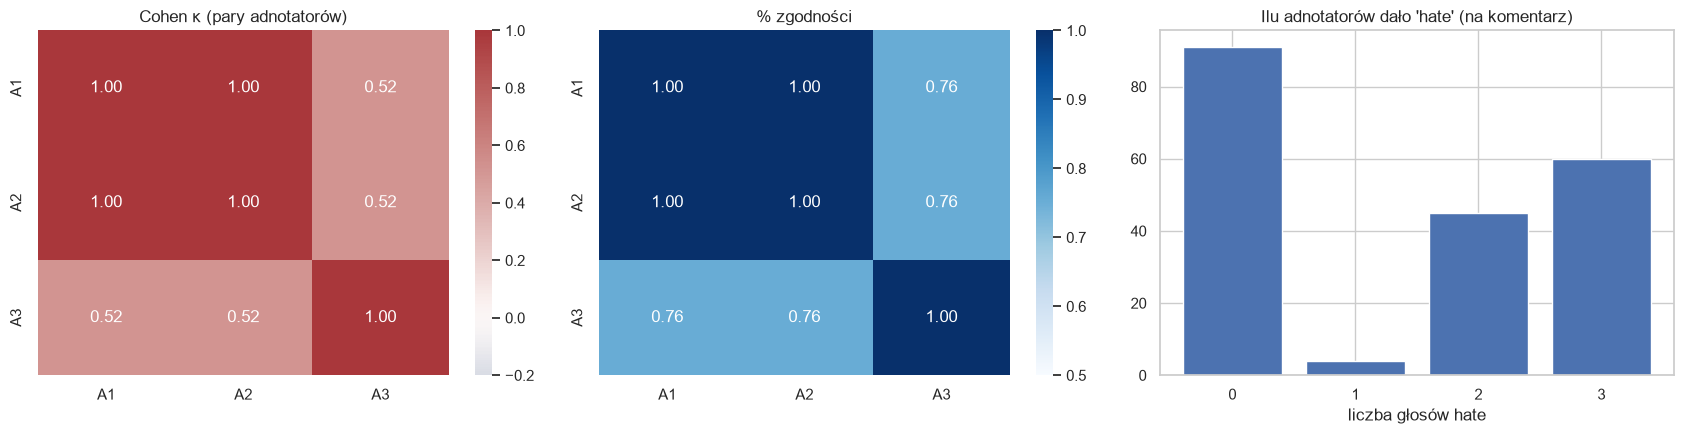

In [47]:
# ---- współczynniki zgodności
kappa_a, pct_a, pabak_a, n_a = pairwise_agreement(ANN)
fk, fk_n = fleiss_kappa(ANN); ac1, ac1_n = gwet_ac1(ANN)
alpha = krippendorff_alpha_nominal(ANN); alpha_lo, alpha_hi = bootstrap_alpha(ANN, n_boot=BOOTSTRAP_N // 2)
off = ~np.eye(len(available), dtype=bool)
agr = {
    "n_items": int(len(ANN)), "n_annotators": len(available),
    "n_items_complete_all_annotators": int(ANN.notna().all(axis=1).sum()),
    "mean_pairwise_percent_agreement": float(np.nanmean(pct_a.values[off])),
    "mean_pairwise_cohen_kappa (Light)": float(np.nanmean(kappa_a.values[off])),
    "mean_pairwise_PABAK": float(np.nanmean(pabak_a.values[off])),
    "fleiss_kappa": fk, "fleiss_kappa_n_items": fk_n,
    "gwet_AC1": ac1, "gwet_AC1_n_items": ac1_n,
    "krippendorff_alpha_nominal": alpha, "krippendorff_alpha_CI95_low": alpha_lo, "krippendorff_alpha_CI95_high": alpha_hi,
}
(DIR_AGR / "agreement_summary.json").write_text(json.dumps(agr, indent=2))
kappa_a.to_csv(DIR_AGR / "pairwise_cohen_kappa.csv"); pct_a.to_csv(DIR_AGR / "pairwise_percent_agreement.csv")
pabak_a.to_csv(DIR_AGR / "pairwise_PABAK.csv"); n_a.to_csv(DIR_AGR / "pairwise_n_items.csv")
display(pd.Series(agr).to_frame("wartość"))

per_ann = pd.DataFrame({"n_oceniono": ANN.notna().sum(), "n_hate": ANN.sum(), "% hate": (100 * ANN.mean()).round(1)})
per_ann.to_csv(DIR_AGR / "per_annotator_stats.csv"); display(per_ann)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.heatmap(kappa_a.astype(float), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-0.2, vmax=1, ax=ax[0]); ax[0].set_title("Cohen κ (pary adnotatorów)")
sns.heatmap(pct_a.astype(float), annot=True, fmt=".2f", cmap="Blues", vmin=0.5, vmax=1, ax=ax[1]); ax[1].set_title("% zgodności")
vote_dist = ANN.sum(axis=1).value_counts().sort_index(); ax[2].bar(vote_dist.index.astype(int).astype(str), vote_dist.values)
ax[2].set_title("Ilu adnotatorów dało 'hate' (na komentarz)"); ax[2].set_xlabel("liczba głosów hate")
plt.tight_layout(); plt.savefig(DIR_FIG / "annotation_agreement.png", dpi=130); plt.show()

**Jak czytać:** przy rzadkiej klasie (hate) κ Cohena i Fleissa mogą być niskie mimo wysokiej zgodności procentowej („paradoks kappy”) – dlatego policzono też **Krippendorff α** (obsługuje braki), **Gwet AC1** i **PABAK**. Przybliżone progi (Landis & Koch / Krippendorff): <0,4 słaba, 0,4–0,6 umiarkowana, 0,6–0,8 dobra, >0,8 bardzo dobra; Krippendorff zaleca α ≥ 0,667 dla wniosków wstępnych.

## 12. Złoty standard (gold) z adnotacji

- `gold` = **większość głosów**; remis (np. 2:2) → `NaN`, dopóki nie zostanie rozstrzygnięty.
- Remisy trafiają do `outputs/annotation/adjudication_template.csv`. Uzupełnij kolumnę `adjudicated_label` (0/1) po wspólnej dyskusji, zapisz jako `outputs/annotation/completed/adjudication.csv` i uruchom komórkę ponownie.
- Dodatkowo: `hate_share` (miękka etykieta) oraz podzbiór jednomyślny (`unanimous`).

In [48]:
adj_path = DIR_ANN_DONE / "adjudication.csv"
adjudicated = None
if adj_path.exists():
    a = pd.read_csv(adj_path, dtype=str); a["adjudicated_label"] = pd.to_numeric(a["adjudicated_label"], errors="coerce")
    adjudicated = a.dropna(subset=["adjudicated_label"]).set_index("item_id")["adjudicated_label"]
    print("Wczytano adjudykację:", len(adjudicated))

G = build_gold(ANN, adjudicated)
G.index.name = "item_id"
GOLD = master.set_index("item_id").join(G)
print(GOLD["gold_status"].value_counts().to_dict())

ties = GOLD[GOLD.gold_status == "tie"][["comment_id", "comment_text"]].reset_index()
ties = ties.join(ANN.reindex(ties["item_id"]).reset_index(drop=True))
ties["adjudicated_label"] = ""
ties.to_csv(DIR_ANN / "adjudication_template.csv", index=False, encoding="utf-8-sig")
print(f"Remisów do rozstrzygnięcia: {len(ties)} -> {DIR_ANN / 'adjudication_template.csv'}")
GOLD.to_csv(DIR_ANN / "gold_standard.csv", encoding="utf-8-sig")
GOLD[["comment_text", "stratum", "votes_hate", "n_annotators", "gold", "gold_status"]].head(10)

{'unanimous': 151, 'majority': 49}
Remisów do rozstrzygnięcia: 0 -> outputs/annotation/adjudication_template.csv


,comment_text,stratum,votes_hate,n_annotators,gold,gold_status
item_id,,,,,,
item_0000,Oddajmy Ukraińcom cały polski nierząd !!! Za darmo oczywiście!!! 😄,S2_half,2,3,1.0,majority
item_0001,Uważajcie tam na siebie!!! Tam jest bombardowanie Rosji ja byłem w Ukrainie i widziałem jak to,S0_none,0,3,0.0,unanimous
item_0002,"Nie walczą o państwowość tylko o Donbas i surowce, które się tam znajdują.",S0_none,0,3,0.0,unanimous
item_0003,Ten taniec nazywa się POGO i był modny w 1980. Jak zwykle ukraińskie niedorobione bydło o 40 lat spóźnione,S3_most,3,3,1.0,unanimous
item_0004,"Ukraincy won z polski, z Europy, do siebie.... cwaniaki, złodzieje",S3_most,3,3,1.0,unanimous
item_0005,"Całe to SS ""Galizien"" jest organizacją zbrodniczą i skompromitowaną. Film oglądają też ludzie z Południowego Podlasia, Lubelszczyzny, Podkarpacia ...",S2_half,2,3,1.0,majority
item_0006,"Mnie też się nie podobają. I hałasujacy ukrainscy pasażerowie w komunikacji miejskiej. Dzieci rozwydzona i bezkarne, paniusie rozmawiają przez tel...",S1_few,3,3,1.0,unanimous
item_0007,prawda jest tak to tak zjebany narud wszystkich nienawidzi petlura stworzyl ludowy ukraine co oni zrobili z tym zamiast ja bronic bydlo ja przes...,S4_all,3,3,1.0,unanimous
item_0008,Za brak zgody od morderców Polskich Rodzin przez ukrainców na skshumacje Polskich ofiar ukraincy mordercy Polaków nie przeprosili ...dlaczego ...b...,S4_all,3,3,1.0,unanimous


## 13. Porównanie adnotacji ręcznej z 10 modelami

Dla każdego modelu na zaadnotowanej próbce: precision / recall / F1 (hate), macro-F1, MCC, κ i AC1 względem złotego standardu, ROC-AUC i PR-AUC (niezależne od progu) oraz wersje **ważone wagami próbkowania** (szacunek dla całej populacji komentarzy). Do tego zgodność każdego modelu z każdym adnotatorem i z miękką etykietą (Spearman z odsetkiem głosów hate).

In [50]:
ev = GOLD[GOLD["gold"].notna()].copy()
ev["gold"] = ev["gold"].astype(int)
cid = ev["comment_id"].values
print(f"Do porównania: {len(ev)} komentarzy z ustalonym gold (z {len(GOLD)}); hate w gold: {ev['gold'].sum()}")

rows = []
for key in MODEL_KEYS:
    pm = PRED[key].set_index("comment_id").loc[cid]
    p = pm["p_hate"].values; yhat = (p >= THRESHOLD).astype(int); y = ev["gold"].values; w = ev["sampling_weight"].values
    m = binary_metrics(y, p, THRESHOLD)
    mw = binary_metrics(y, p, THRESHOLD, sample_weight=w)
    lo, hi = bootstrap_ci(y, yhat, "macro_f1", n_boot=BOOTSTRAP_N)
    ac1_m, _ = gwet_ac1(pd.DataFrame({"gold": y, "model": yhat}).astype(float))
    # najlepszy próg (optymistyczny – dobrany na tej samej próbce)
    ths = np.linspace(0.05, 0.95, 91); f1s = [binary_metrics(y, p, t)["f1_hate"] for t in ths]
    soft_rho = spearmanr(p, ev["hate_share"].values).correlation
    rows.append({"model": key,
                 **{k: m[k] for k in ["accuracy", "precision_hate", "recall_hate", "f1_hate", "macro_f1", "mcc", "cohen_kappa", "roc_auc", "pr_auc", "ece"]},
                 "macro_f1_ci_low": lo, "macro_f1_ci_high": hi, "gwet_ac1": ac1_m,
                 "W_precision_hate": mw["precision_hate"], "W_recall_hate": mw["recall_hate"], "W_f1_hate": mw["f1_hate"], "W_macro_f1": mw["macro_f1"],
                 "best_threshold_f1": float(ths[int(np.argmax(f1s))]), "best_threshold_f1_value": float(np.max(f1s)),
                 "spearman_vs_annotator_share": soft_rho, "n_pred_hate": int(yhat.sum())})
CMP = pd.DataFrame(rows).set_index("model")
CMP.to_csv(DIR_CMP / "models_vs_gold.csv")
CMP.round(3)

Do porównania: 200 komentarzy z ustalonym gold (z 200); hate w gold: 105


,accuracy,precision_hate,recall_hate,f1_hate,macro_f1,mcc,cohen_kappa,roc_auc,pr_auc,ece,...,macro_f1_ci_high,gwet_ac1,W_precision_hate,W_recall_hate,W_f1_hate,W_macro_f1,best_threshold_f1,best_threshold_f1_value,spearman_vs_annotator_share,n_pred_hate
model,,,,,,,,,,,,,,,,,,,,,
herbert_hs,0.735,0.686,0.914,0.784,0.721,0.492,0.459,0.817,0.821,0.101,...,0.784,0.496,0.610,0.746,0.671,0.740,0.40,0.789,0.591,140
herbert_hs_banpl,0.690,0.731,0.648,0.687,0.690,0.385,0.382,0.750,0.714,0.257,...,0.752,0.380,0.727,0.277,0.401,0.612,0.06,0.742,0.478,93
herbert_base_poleval,0.695,0.696,0.743,0.719,0.693,0.387,0.386,0.710,0.701,0.218,...,0.756,0.394,0.638,0.440,0.521,0.667,0.33,0.730,0.404,112
herbert_base_banpl,0.690,0.709,0.695,0.702,0.690,0.379,0.379,0.748,0.717,0.255,...,0.753,0.381,0.654,0.335,0.443,0.629,0.05,0.745,0.462,103
roberta_base_poleval,0.590,0.653,0.467,0.544,0.586,0.199,0.190,0.615,0.640,0.345,...,0.653,0.188,0.509,0.161,0.245,0.517,0.05,0.631,0.244,75
roberta_base_banpl,0.635,0.674,0.590,0.629,0.635,0.275,0.273,0.699,0.685,0.326,...,0.705,0.270,0.579,0.270,0.368,0.583,0.05,0.657,0.350,92
polbert_cb,0.645,0.660,0.667,0.664,0.644,0.288,0.288,0.687,0.659,0.293,...,0.713,0.292,0.592,0.349,0.439,0.619,0.10,0.735,0.383,106
polbert_cb_banpl,0.655,0.691,0.619,0.653,0.655,0.314,0.312,0.730,0.722,0.322,...,0.720,0.310,0.695,0.303,0.422,0.621,0.05,0.704,0.438,94
polbert_base_poleval,0.615,0.675,0.514,0.584,0.613,0.245,0.238,0.686,0.686,0.358,...,0.679,0.234,0.623,0.185,0.285,0.545,0.15,0.604,0.388,80


ensemble_mean_prob        F1(hate)=0.687 macroF1=0.690 P=0.731 R=0.648
ensemble_majority_vote    F1(hate)=0.667 macroF1=0.675 P=0.722 R=0.619


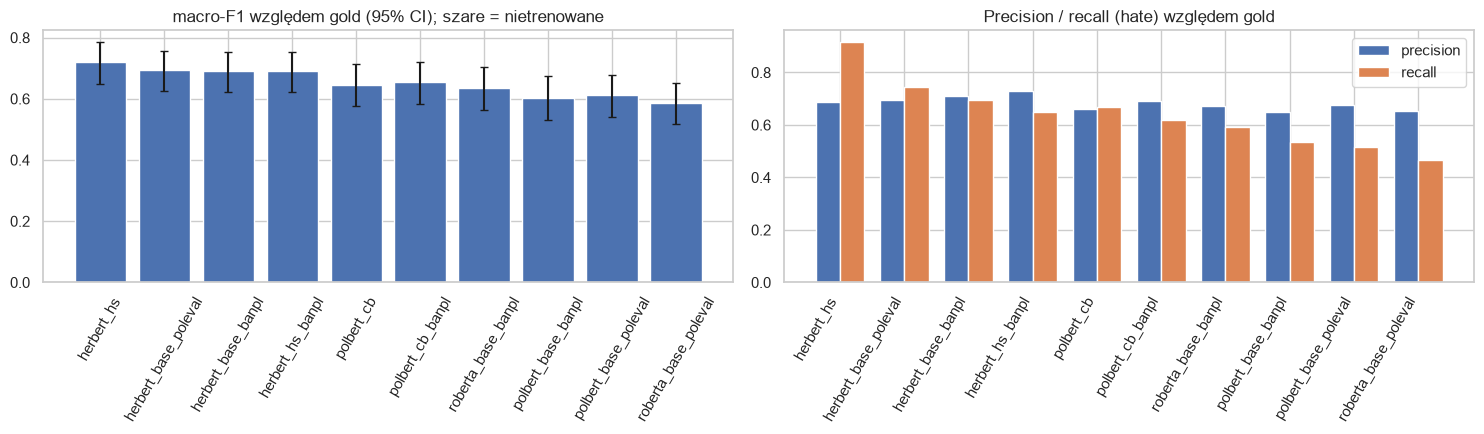

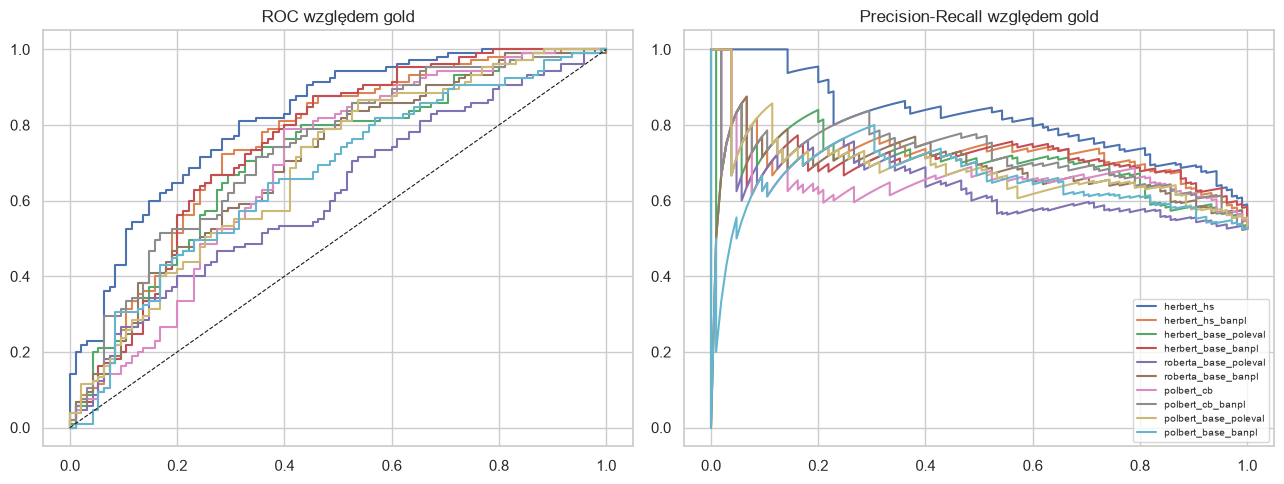

In [52]:
# ensemble jako dodatkowy "model"
for name, col in [("ensemble_mean_prob", "mean_p_hate_ensemble"), ("ensemble_majority_vote", "ensemble_majority")]:
    v = wide.set_index("comment_id").loc[cid, col].values
    m = binary_metrics(ev["gold"].values, v, THRESHOLD if "mean" in name else 0.5)
    print(f"{name:25s} F1(hate)={m['f1_hate']:.3f} macroF1={m['macro_f1']:.3f} P={m['precision_hate']:.3f} R={m['recall_hate']:.3f}")

# wykresy
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
order = CMP.sort_values("f1_hate", ascending=False).index
err = np.vstack([CMP.loc[order, "macro_f1"] - CMP.loc[order, "macro_f1_ci_low"], CMP.loc[order, "macro_f1_ci_high"] - CMP.loc[order, "macro_f1"]])
ax[0].bar(order, CMP.loc[order, "macro_f1"], yerr=err, capsize=3, color=[ "#4c72b0"])
ax[0].set_title("macro-F1 względem gold (95% CI); szare = nietrenowane"); ax[0].tick_params(axis="x", rotation=60)
x = np.arange(len(order)); wd = 0.38
ax[1].bar(x - wd/2, CMP.loc[order, "precision_hate"], wd, label="precision"); ax[1].bar(x + wd/2, CMP.loc[order, "recall_hate"], wd, label="recall")
ax[1].set_xticks(x); ax[1].set_xticklabels(order, rotation=60, ha="right"); ax[1].set_title("Precision / recall (hate) względem gold"); ax[1].legend()
plt.tight_layout(); plt.savefig(DIR_FIG / "models_vs_gold_bars.png", dpi=130); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for key in MODEL_KEYS:
    p = PRED[key].set_index("comment_id").loc[cid, "p_hate"].values
    if ev["gold"].nunique() < 2: break
    fpr, tpr, _ = roc_curve(ev["gold"], p); ax[0].plot(fpr, tpr, label=key)
    pr, rc, _ = precision_recall_curve(ev["gold"], p); ax[1].plot(rc, pr, label=key)
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_title("ROC względem gold"); ax[1].set_title("Precision-Recall względem gold"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(DIR_FIG / "models_vs_gold_roc_pr.png", dpi=130); plt.show()

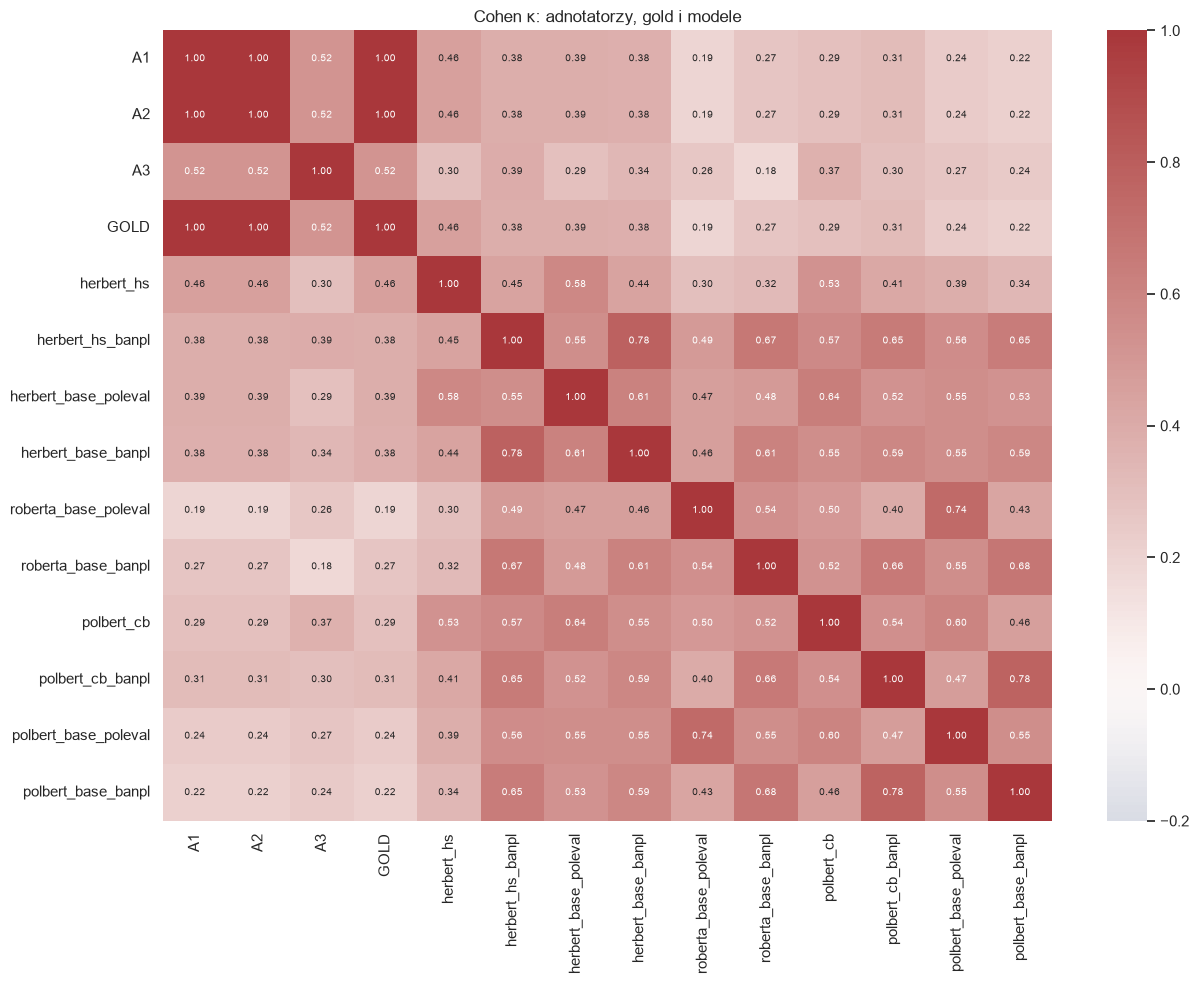

,alpha_with,alpha_humans_only,delta
rater_added,,,
herbert_hs,0.527,0.671,-0.145
herbert_hs_banpl,0.529,0.671,-0.142
herbert_base_poleval,0.510,0.671,-0.161
herbert_base_banpl,0.517,0.671,-0.154
roberta_base_poleval,0.443,0.671,-0.228
roberta_base_banpl,0.457,0.671,-0.215
polbert_cb,0.493,0.671,-0.179
polbert_cb_banpl,0.491,0.671,-0.181
polbert_base_poleval,0.460,0.671,-0.211


In [53]:
# pełna macierz κ: adnotatorzy + gold + modele (na wspólnej próbce)
R = ANN.reindex(ev.index).copy()
R["GOLD"] = ev["gold"].astype(float)
for key in MODEL_KEYS:
    R[key] = (PRED[key].set_index("comment_id").loc[cid, "p_hate"].values >= THRESHOLD).astype(float)
k_all, pct_all, _, _ = pairwise_agreement(R)
k_all.to_csv(DIR_CMP / "kappa_all_raters.csv")
plt.figure(figsize=(13, 10)); sns.heatmap(k_all.astype(float), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-0.2, vmax=1, annot_kws={"size": 7})
plt.title("Cohen κ: adnotatorzy, gold i modele"); plt.tight_layout(); plt.savefig(DIR_FIG / "kappa_all_raters.png", dpi=130); plt.show()

# model jako "piąty adnotator": czy dodanie go obniża α?
base_alpha = krippendorff_alpha_nominal(R[available])
rows = [{"rater_added": k, "alpha_with": krippendorff_alpha_nominal(R[available + [k]]), "alpha_humans_only": base_alpha} for k in MODEL_KEYS]
alpha_add = pd.DataFrame(rows).assign(delta=lambda d: d.alpha_with - d.alpha_humans_only).set_index("rater_added")
alpha_add.to_csv(DIR_CMP / "krippendorff_alpha_adding_model.csv"); alpha_add.round(3)

In [55]:
# analiza błędów najlepszego (nie-bazowego) modelu względem gold
best = CMP.sort_values("f1_hate", ascending=False).index[0]
print("Najlepszy model wg F1(hate) względem gold:", best)
e = ev.copy(); e["p_hate"] = PRED[best].set_index("comment_id").loc[cid, "p_hate"].values
e["pred"] = (e.p_hate >= THRESHOLD).astype(int)
fp = e[(e.pred == 1) & (e.gold == 0)].sort_values("p_hate", ascending=False)
fn = e[(e.pred == 0) & (e.gold == 1)].sort_values("p_hate")
cols = ["comment_text", "p_hate", "votes_hate", "n_annotators", "stratum"]
print(f"Fałszywie pozytywne ({len(fp)}):"); display(fp[cols].head(10))
print(f"Fałszywie negatywne ({len(fn)}):"); display(fn[cols].head(10))
fp[cols].to_csv(DIR_CMP / f"errors_false_positives_{best}.csv", encoding="utf-8-sig")
fn[cols].to_csv(DIR_CMP / f"errors_false_negatives_{best}.csv", encoding="utf-8-sig")

Najlepszy model wg F1(hate) względem gold: herbert_hs
Fałszywie pozytywne (44):


,comment_text,p_hate,votes_hate,n_annotators,stratum
item_id,,,,,
item_0114,Ładnie Ukraińcy biją ruskiego kacapa. Jeszcze kilka miesięcy i będzie po wojnie.,0.929914,0,3,S1_few
item_0161,Jesteś zdrajcą Polski i Europy Ukraina zaczęła ten konflikt,0.920819,0,3,S3_most
item_0175,"Ty to napewno, będziesz przeklęty na wieki.Weś swoją partię i koalicję i zapierdalajcie walczyć zdrajcy za Ukrainę.A od Polaków się odpierdol,to n...",0.915810,0,3,S4_all
item_0118,Tłuc ruskich bolszewikow zarazę ziemni a Putina bolszewika zniszczyć ubić Ukraino brawo brawo 👍🇵🇱🇵🇱🇵🇱🇵🇱🇵🇱,0.912147,1,3,S4_all
item_0160,a ruskie onuce w to wierzą...jesteście zgrają prymitywów !!!WIWAT UKRAINA CIULE !!!🤣🤣🤣,0.911554,0,3,S4_all
item_0164,Jak byś Ruskich nie znał oni na Ukrainie by nie skończyli 😁😁😁,0.907709,0,3,S1_few
item_0179,"Polecam ten kanał ABW i SKW. Macie tu ruskich troli jak na widelcu, pomijam UPA itd, skurwysyny z Rosji zawsze chceili byc księgowymi polsko-ukrai...",0.880508,0,3,S4_all
item_0117,Propaganda kacapów jeśli chodzi o ukrainę jest prawdą.,0.873576,0,3,S1_few
item_0147,Premier Bawarie jest dupkiem : zabierzemy pieniadze naszym rencistom i damy Ukraincom serdecznie witamy .!!!,0.868704,0,3,S2_half


Fałszywie negatywne (9):


,comment_text,p_hate,votes_hate,n_annotators,stratum
item_id,,,,,
item_0119,Ukraina to wynalazek Niemiecki.,0.110847,2,3,S0_none
item_0054,A chuj z Ukrainą szczerze 😂,0.166710,2,3,S2_half
item_0046,Na front !!!! Zdrowe byki a Komik Ukrainy prosi o pomoc inne kraje .Dobry teatr!!!,0.178050,2,3,S0_none
item_0081,"Napierd...I w Donbas kilka lat,na livelink można było oglądać egzekucję azowcow na cywilach ze wsch.Ukrainy. Idealna taktyka na opóźnianie 👍👍",0.260221,2,3,S1_few
item_0019,Nareszcie mówisz prawdę o tych ukraincach,0.289572,2,3,S1_few
item_0146,"a kto chce bronic ukrainy i bialorusi skoro rosja i biali to jeden wał, w sumie ukry też",0.325722,2,3,S0_none
item_0033,"Ukraińcy swą wdzięczność okazują- śpiewając w Polsce nieformalny hymn UPA- "" czerwona kalina ""- i wykrzykując banderowskie pozdrowienie "" SŁAWA UK...",0.420278,2,3,S1_few
item_0025,Ale wojna 😂😂😂 biedne ukraince 😂😂😂😂😂🤮🤮🤮🤮🤮🤮🤮,0.436159,3,3,S1_few
item_0021,Twój dom jest na Ukrainie a nie tutaj i dobrze a co wy myślicie że będą mieszkać za darmo a my będziemy na was robić.,0.466414,3,3,S0_none


## 14. Podsumowanie i spis zapisanych plików

In [56]:
final = {
    "modele_dotrenowane": {k: str(MODEL_REGISTRY[k]["path"]) for k in MODEL_KEYS if (MODEL_REGISTRY[k]["path"] / "training_info.json").exists()},
    "ewaluacja_18": str(DIR_EVAL / "evaluation_all_18.csv"),
    "predykcje_comments": str(DIR_PRED), "adnotacja": str(DIR_ANN), "zgodnosc": str(DIR_AGR), "porownanie": str(DIR_CMP), "wykresy": str(DIR_FIG),
}
(OUT / "RUN_SUMMARY.json").write_text(json.dumps(final, indent=2, ensure_ascii=False))
print(json.dumps(final, indent=2, ensure_ascii=False))
print("\nPliki w outputs/:")
for p in sorted(OUT.rglob("*")):
    if p.is_file() and "models" not in p.parts[:2]:
        print(" ", p.relative_to(OUT))

{
  "modele_dotrenowane": {
    "herbert_hs_banpl": "outputs/models/herbert_hs_banpl",
    "herbert_base_poleval": "outputs/models/herbert_base_poleval",
    "herbert_base_banpl": "outputs/models/herbert_base_banpl",
    "roberta_base_poleval": "outputs/models/roberta_base_poleval",
    "roberta_base_banpl": "outputs/models/roberta_base_banpl",
    "polbert_cb_banpl": "outputs/models/polbert_cb_banpl",
    "polbert_base_poleval": "outputs/models/polbert_base_poleval",
    "polbert_base_banpl": "outputs/models/polbert_base_banpl"
  },
  "ewaluacja_18": "outputs/evaluation/evaluation_all_18.csv",
  "predykcje_comments": "outputs/comments_predictions",
  "adnotacja": "outputs/annotation",
  "zgodnosc": "outputs/agreement",
  "porownanie": "outputs/model_vs_annotation",
  "wykresy": "outputs/figures"
}

Pliki w outputs/:
  RUN_SUMMARY.json
  agreement/agreement_summary.json
  agreement/pairwise_PABAK.csv
  agreement/pairwise_cohen_kappa.csv
  agreement/pairwise_n_items.csv
  agreement/pair

### Jak użyć dotrenowanego modelu później (bez fine-tuningu)
```python
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch
path = "outputs/models/roberta_banpl"
tok = AutoTokenizer.from_pretrained(path); model = AutoModelForSequenceClassification.from_pretrained(path).eval()
x = tok(["przykładowy komentarz"], return_tensors="pt", truncation=True, max_length=512)
p_hate = torch.softmax(model(**x).logits, -1)[0, 1].item()   # 1 = hate
```